# TFM — Capítulo 5: Desarrollo / Implementación (SkillCorner Open Data, por partido)

**Identificación de fases tácticas en fútbol utilizando clustering y datos espaciales de alta frecuencia**

Este notebook ejecuta el pipeline completo de la metodología (capítulo 4) sobre datos **reales**
de 9 partidos de la A-League 2024/25 (SkillCorner Open Data, cargados vía `kloppy`). Cada partido
y cada equipo se procesan de forma **independiente** (un modelo de clustering + HMM por cada
combinación partido-equipo), ya que el nivel y el estilo de los equipos no es homogéneo entre
partidos — mezclar todos los partidos en un único modelo habría forzado arquetipos tácticos
artificialmente promediados entre equipos muy distintos.

Este notebook parte de una versión anterior que usaba un generador sintético de partidos para
validar la metodología con un ground truth conocido (útil para comprobar que el pipeline
detectaba correctamente un número de fases determinado de antemano). Esa validación cumplió su
propósito y ya no es necesaria aquí: **todo el código de este notebook opera exclusivamente sobre
los 9 partidos reales de SkillCorner**, sin ningún dato generado artificialmente. Se mantienen dos
correcciones importantes heredadas de esa fase de validación:

1. **`extraer_fases()` fusiona de verdad los segmentos cortos** con el segmento adyacente más
   parecido (apartado 4.5), en lugar de descartarlos silenciosamente.
2. **Manejo de excepciones más estricto** en la segmentación temporal: solo se cae al *fallback*
   GMM si `hmmlearn` no está instalado, no si el HMM falla por cualquier otro motivo (en cuyo caso
   se informa explícitamente del error en pantalla).

Además, en esta revisión se han corregido dos problemas detectados al auditar el notebook:
un filtro incompleto en la función `dibujar_frame` (podía mezclar jugadores de partidos distintos
si compartían el mismo número de frame) y una variable (`partidos`) reutilizada con dos
significados distintos en celdas diferentes. Ambos se explican en el punto exacto del notebook en
el que se corrigen.

**Nota de reproducibilidad:** este notebook necesita descargar los datos de tracking de
SkillCorner a través de `kloppy` (que a su vez usa Git LFS internamente), por lo que requiere
ejecutarse en un entorno con acceso completo a internet (p. ej. Google Colab). Se ha revisado
línea a línea y no queda ninguna referencia a variables no definidas en el orden de ejecución,
pero la carga real de los 9 partidos solo puede confirmarse ejecutando la celda de la Sección 5.2
en un entorno con esa conectividad.


## 5.1 Configuración global del experimento

Se centralizan los parámetros del pipeline: frecuencia de referencia tras homogeneización,
duración mínima de una fase, ventana de suavizado temporal y semilla aleatoria. Fijar estos
valores en un único lugar (en vez de repetirlos sueltos en cada celda) evita incoherencias si se
cambia uno de ellos a mitad de notebook, y hace explícito, de un vistazo, qué decisiones
metodológicas del capítulo 4 se están aplicando:

- `FPS_REFERENCIA = 10`: frecuencia a la que se remuestrea el tracking al cargarlo (apartado 4.1).
  SkillCorner se solicita directamente a esta frecuencia (`sample_rate=1/FPS_REFERENCIA` en la
  Sección 5.2), en vez de cargar a la frecuencia nativa y remuestrear después.
- `MIN_DURACION_FASE_S = 3`: duración mínima para que un segmento cuente como fase táctica
  (apartado 4.5); los segmentos más cortos se fusionan con el vecino más parecido.
- `VENTANA_SUAVIZADO_S`: ventana de agregación temporal de las variables colectivas (apartado 4.3),
  convertida aquí de segundos a número de frames usando `FPS_REFERENCIA`.
- `SEMILLA = 42`: semilla única para K-means y el HMM, de modo que los resultados de este notebook
  sean reproducibles entre ejecuciones.


In [1]:
import os, warnings
import numpy as np
import pandas as pd
warnings.filterwarnings('ignore')

!pip -q install kloppy hmmlearn

FPS_REFERENCIA = 10          # frecuencia de referencia tras homogeneización (apartado 4.1)
MIN_DURACION_FASE_S = 3      # duración mínima de fase (apartado 4.5)
VENTANA_SUAVIZADO_S = 2.1    # ventana temporal de agregación (apartado 4.3)
VENTANA_SUAVIZADO_S = int(VENTANA_SUAVIZADO_S * FPS_REFERENCIA)
SEMILLA = 42

np.random.seed(SEMILLA)
print('Configuración cargada. FPS de referencia:', FPS_REFERENCIA)


Configuración cargada. FPS de referencia: 10


## 5.2 Carga y unificación de las fuentes de datos

### 5.2.1 Fuente de datos: SkillCorner Open Data (9 partidos reales)

A diferencia de una versión anterior de este notebook, que recurría a un generador sintético
cuando la fuente real no estaba disponible, esta versión trabaja **exclusivamente con datos
reales**: los 9 partidos de la A-League 2024/25 publicados por SkillCorner con `status='closed'`
(los que tienen tracking completo verificado). No hay ningún mecanismo de *fallback* a datos
artificiales — si la carga de un partido concreto falla (por ejemplo, por un problema de red
puntual), ese partido se registra en la lista `fallos` y simplemente se omite del análisis, en
lugar de sustituirlo por datos simulados.

La función `reshape_skillcorner()` hace tres cosas sobre el DataFrame "ancho" que devuelve
`kloppy` (una columna `PLAYERID_x` / `PLAYERID_y` por jugador):

1. Identifica, a partir de los metadatos del partido, qué `player_id` pertenece al equipo local y
   cuál al visitante.
2. Reestructura los datos a formato "largo" (`match, frame, time, team, player, x, y`), con una
   fila por jugador y frame en vez de una columna por jugador — el mismo formato homogéneo usado
   en todo el resto del pipeline (capítulo 4).
3. Normaliza la orientación de ataque: en el segundo periodo se invierte el signo de `x` para que
   el equipo local ataque siempre hacia la derecha durante todo el partido (apartado 4.2), evitando
   que "profundidad" o "distancia a portería rival" cambien de significado tras el descanso.

El bucle principal carga los 9 partidos uno a uno y guarda cada uno en el diccionario
`partidos = {match_id: DataFrame}`. **Importante:** esta variable `partidos` se reutiliza más
abajo (Sección 5.2.2) para almacenar el DataFrame homogéneo de cada partido — no debe confundirse
con la lista de IDs de partido que se usa, con otro nombre (`partidos_team`), en la Sección 5.6.


In [3]:
# ============================================================
# 5.2 SkillCorner Open Data — CARGA DE LA LISTA DE PARTIDOS
#     Dataset principal
# ============================================================

from kloppy import skillcorner
import numpy as np
import pandas as pd


# Los 9 partidos con status='closed'
MATCH_IDS = [
    1886347, 1899585, 1925299, 1996435, 2006229,
    2011166, 2013725, 2015213, 2017461
]


def reshape_skillcorner(dataset, df, match_id):
    """
    Convierte el formato wide de SkillCorner/Kloppy:

        frame_id, timestamp, period_id,
        ball_x, ball_y,
        PLAYERID_x, PLAYERID_y, ...

    al formato homogéneo del pipeline:

        [match, frame, time, team, player, x, y]

    donde:
        team = {'home', 'away', 'ball'}

    También normaliza la orientación:
    en el segundo periodo se refleja x para que
    el equipo local ataque siempre hacia la derecha.
    """

    # --------------------------------------------------------
    # 1. Construir mapa player_id -> home / away
    # --------------------------------------------------------

    player_team = {}

    for team in dataset.metadata.teams:

        if str(team.ground).lower() == 'home':
            etiqueta = 'home'

        elif str(team.ground).lower() == 'away':
            etiqueta = 'away'

        else:
            raise ValueError(
                f"No se pudo identificar home/away para "
                f"el equipo {team}"
            )

        for player in team.players:
            player_team[str(player.player_id)] = etiqueta


    # --------------------------------------------------------
    # 2. Columnas básicas
    # --------------------------------------------------------

    columnas_base = [
        'frame_id',
        'timestamp',
        'period_id'
    ]

    for col in columnas_base:
        if col not in df.columns:
            raise KeyError(
                f"No se encuentra la columna '{col}' "
                f"en el DataFrame de SkillCorner."
            )


    # --------------------------------------------------------
    # 3. Extraer jugadores
    #
    # Las columnas tienen esta estructura:
    #
    #   51009_x
    #   51009_y
    #   51009_d
    #   51009_s
    #
    # Nosotros solo necesitamos _x y _y.
    # --------------------------------------------------------

    player_ids = set()

    for col in df.columns:

        if col.endswith('_x'):

            player_id = col[:-2]

            # Comprobamos que también exista la coordenada y
            if f'{player_id}_y' in df.columns:
                player_ids.add(player_id)


    # --------------------------------------------------------
    # 4. Crear filas de jugadores
    # --------------------------------------------------------

    filas_jugadores = []

    for player_id in sorted(player_ids):

        # Si el jugador no aparece en metadata, lo avisamos
        # pero no detenemos todo el partido.
        if player_id not in player_team:
            continue

        team = player_team[player_id]

        x_col = f'{player_id}_x'
        y_col = f'{player_id}_y'

        tmp = df[
            ['frame_id', 'timestamp', 'period_id', x_col, y_col]
        ].copy()

        tmp = tmp.rename(
            columns={
                'frame_id': 'frame',
                'timestamp': 'time',
                x_col: 'x',
                y_col: 'y'
            }
        )

        tmp['team'] = team
        tmp['player'] = player_id

        filas_jugadores.append(
            tmp[
                [
                    'frame',
                    'time',
                    'period_id',
                    'team',
                    'player',
                    'x',
                    'y'
                ]
            ]
        )


    # --------------------------------------------------------
    # 5. Concatenar jugadores
    # --------------------------------------------------------

    if filas_jugadores:

        jugadores = pd.concat(
            filas_jugadores,
            ignore_index=True
        )

    else:

        jugadores = pd.DataFrame(
            columns=[
                'frame',
                'time',
                'period_id',
                'team',
                'player',
                'x',
                'y'
            ]
        )


    # --------------------------------------------------------
    # 6. Añadir balón
    # --------------------------------------------------------

    if 'ball_x' not in df.columns or 'ball_y' not in df.columns:
        raise KeyError(
            "No se encuentran ball_x / ball_y en el DataFrame."
        )

    balon = df[
        [
            'frame_id',
            'timestamp',
            'period_id',
            'ball_x',
            'ball_y'
        ]
    ].copy()

    balon = balon.dropna(
        subset=['ball_x', 'ball_y']
    )

    balon = balon.rename(
        columns={
            'frame_id': 'frame',
            'timestamp': 'time',
            'ball_x': 'x',
            'ball_y': 'y'
        }
    )

    balon['team'] = 'ball'
    balon['player'] = np.nan

    balon = balon[
        [
            'frame',
            'time',
            'period_id',
            'team',
            'player',
            'x',
            'y'
        ]
    ]


    # --------------------------------------------------------
    # 7. Unir jugadores + balón
    # --------------------------------------------------------

    out = pd.concat(
        [
            jugadores,
            balon
        ],
        ignore_index=True
    )


    # --------------------------------------------------------
    # 8. Orientación
    #
    # En el segundo periodo:
    #
    #       x -> -x
    #
    # para que el equipo local ataque siempre
    # hacia la derecha.
    # --------------------------------------------------------

    mask_periodo_2 = out['period_id'] == 2

    out.loc[mask_periodo_2, 'x'] = (
        -out.loc[mask_periodo_2, 'x']
    )


    # --------------------------------------------------------
    # 9. Añadir ID del partido
    # --------------------------------------------------------

    out['match'] = match_id


    # --------------------------------------------------------
    # 10. Orden y formato final
    # --------------------------------------------------------

    out = out[
        [
            'match',
            'frame',
            'time',
            'team',
            'player',
            'x',
            'y'
        ]
    ]

    out = out.sort_values(
        ['frame', 'team', 'player'],
        na_position='last'
    ).reset_index(drop=True)


    return out


# ============================================================
# CARGA DE LOS 9 PARTIDOS
# ============================================================

partidos = {}
fallos = []


for mid in MATCH_IDS:

    try:

        ds = skillcorner.load_open_data(
            match_id=mid,
            sample_rate=1 / FPS_REFERENCIA,
            coordinates='skillcorner',
            only_alive=True,
        )


        # ----------------------------------------------------
        # DataFrame en formato WIDE
        # ----------------------------------------------------

        df_kloppy = ds.to_df()


        # ----------------------------------------------------
        # Diagnóstico del primer partido
        # ----------------------------------------------------

        if mid == MATCH_IDS[0]:

            print('=== DIAGNÓSTICO (primer partido) ===')

            print(
                'columnas:',
                df_kloppy.columns.tolist()
            )

            print(
                'shape:',
                df_kloppy.shape
            )

            print(
                '\nEquipos:'
            )

            for team in ds.metadata.teams:
                print(
                    f'  {team.ground}: '
                    f'{team.name} '
                    f'(ID={team.team_id}) '
                    f'[{len(team.players)} jugadores]'
                )

            print(
                '\nPrimeras filas:'
            )

            print(
                df_kloppy.head(3).to_string()
            )


        # ----------------------------------------------------
        # Transformación a formato homogéneo
        # ----------------------------------------------------

        partidos[mid] = reshape_skillcorner(
            ds,
            df_kloppy,
            mid
        )


        # ----------------------------------------------------
        # Estadísticas
        # ----------------------------------------------------

        df_partido = partidos[mid]

        print(
            f'[{mid}] OK — '
            f'{df_partido.shape[0]} filas, '
            f'{df_partido["frame"].nunique()} frames'
        )


        print(
            '     jugadores:',
            df_partido[
                df_partido['team'].isin(['home', 'away'])
            ]['player'].nunique()
        )

        print(
            '     home:',
            df_partido[
                df_partido['team'] == 'home'
            ]['player'].nunique()
        )

        print(
            '     away:',
            df_partido[
                df_partido['team'] == 'away'
            ]['player'].nunique()
        )


    except Exception as e:

        fallos.append(
            (
                mid,
                f'{type(e).__name__}: {e}'
            )
        )

        print(
            f'[{mid}] FALLO — '
            f'{type(e).__name__}: {e}'
        )


# ============================================================
# RESUMEN FINAL
# ============================================================

print(
    '\nPartidos cargados:',
    list(partidos.keys())
)

print(
    'Fallos:',
    fallos if fallos else 'ninguno'
)


=== DIAGNÓSTICO (primer partido) ===
columnas: ['period_id', 'timestamp', 'frame_id', 'ball_state', 'ball_owning_team_id', 'ball_x', 'ball_y', 'ball_z', 'ball_speed', '51009_x', '51009_y', '51009_d', '51009_s', '176224_x', '176224_y', '176224_d', '176224_s', '51649_x', '51649_y', '51649_d', '51649_s', '50983_x', '50983_y', '50983_d', '50983_s', '735578_x', '735578_y', '735578_d', '735578_s', '50978_x', '50978_y', '50978_d', '50978_s', '735574_x', '735574_y', '735574_d', '735574_s', '795507_x', '795507_y', '795507_d', '795507_s', '795505_x', '795505_y', '795505_d', '795505_s', '735573_x', '735573_y', '735573_d', '735573_s', '966120_x', '966120_y', '966120_d', '966120_s', '285188_x', '285188_y', '285188_d', '285188_s', '51667_x', '51667_y', '51667_d', '51667_s', '33697_x', '33697_y', '33697_d', '33697_s', '51713_x', '51713_y', '51713_d', '51713_s', '133498_x', '133498_y', '133498_d', '133498_s', '14736_x', '14736_y', '14736_d', '14736_s', '23418_x', '23418_y', '23418_d', '23418_s', '1335

[1899585] OK — 89342 filas, 2882 frames
     jugadores: 30
     home: 15
     away: 15


[1925299] OK — 115764 filas, 3508 frames
     jugadores: 32
     home: 16
     away: 16


[1996435] OK — 98952 filas, 3192 frames
     jugadores: 30
     home: 14
     away: 16


[2006229] OK — 105369 filas, 3193 frames
     jugadores: 32
     home: 16
     away: 16


[2011166] OK — 89727 filas, 2719 frames
     jugadores: 32
     home: 16
     away: 16


[2013725] OK — 95511 filas, 3081 frames
     jugadores: 30
     home: 16
     away: 14


[2015213] OK — 101805 filas, 3085 frames
     jugadores: 32
     home: 16
     away: 16


[2017461] OK — 92433 filas, 2801 frames
     jugadores: 32
     home: 16
     away: 16

Partidos cargados: [1886347, 1899585, 1925299, 1996435, 2006229, 2011166, 2013725, 2015213, 2017461]
Fallos: ninguno


Esta celda es una comprobación estructural rápida sobre el objeto `ds` que ha quedado en memoria
tras el bucle de carga anterior (es decir, sobre el **último** partido cargado, `MATCH_IDS[-1]`,
ya que `ds` es la variable de bucle de la celda anterior). No aporta datos nuevos al pipeline: es
únicamente una inspección manual de qué atributos expone el objeto `Dataset` de kloppy y el objeto
`Metadata` (equipos, jugadores, periodos), útil para depurar si en el futuro se necesita extraer
algún campo adicional (por ejemplo, la posición habitual de cada jugador) que no se esté usando
todavía en `reshape_skillcorner()`.


In [4]:
print("=== METADATA ===")
print(ds.metadata)

print("\n=== ATRIBUTOS DE METADATA ===")
print([a for a in dir(ds.metadata) if not a.startswith("_")])

print("\n=== TEAMS ===")
print(ds.metadata.teams)

print("\n=== ATRIBUTOS DEL DATASET ===")
print([a for a in dir(ds) if not a.startswith("_")])


=== METADATA ===
Metadata(periods=[Period(id=1, start_timestamp=datetime.timedelta(seconds=251), end_timestamp=datetime.timedelta(seconds=3021), prev_period=None, next_period=Period(id=2, start_timestamp=datetime.timedelta(seconds=3967), end_timestamp=datetime.timedelta(seconds=7042), prev_period=..., next_period=None)), Period(id=2, start_timestamp=datetime.timedelta(seconds=3967), end_timestamp=datetime.timedelta(seconds=7042), prev_period=Period(id=1, start_timestamp=datetime.timedelta(seconds=251), end_timestamp=datetime.timedelta(seconds=3021), prev_period=None, next_period=...), next_period=None)], teams=[Team(team_id=868, name='Melbourne Victory Football Club', ground=home, starting_formation=None, formations=<TimeContainer>, players=[<Player name='Alexander Badolato' player_id='795521'>, <Player name='Nishan Velupillay' player_id='50955'>, <Player name='Zinédine Machach' player_id='11117'>, <Player name='Reno Piscopo' player_id='51714'>, <Player name='Clarismario Santos Rodrigu

### 5.2.2 Unificación de los 9 partidos en un único DataFrame

Se concatenan los DataFrames homogéneos de los partidos cargados correctamente
(`partidos.values()`) en un único `tracking`, añadiendo la columna `match` como clave para poder
volver a separar los partidos en cualquier punto posterior del pipeline. A partir de aquí, todas
las funciones de variables y de clustering (secciones 5.3 y 5.4) operan sobre este `tracking`
unificado, pero siempre agrupando por `match` (y `team`) para no mezclar información entre
partidos distintos.


In [5]:
tracking = pd.concat(
    partidos.values(),
    ignore_index=True
)

print(tracking.columns.tolist())
print(tracking.shape)
print(tracking['match'].nunique())
print(tracking['match'].unique())


['match', 'frame', 'time', 'team', 'player', 'x', 'y']
(883613, 7)
9
[1886347 1899585 1925299 1996435 2006229 2011166 2013725 2015213 2017461]


### Comprobaciones de calidad tras la homogeneización

Las siguientes celdas son verificaciones básicas de calidad de datos, en línea con el apartado 4.2
(preprocesamiento): comprobar que las columnas y la forma del DataFrame son las esperadas, que el
número de frames por equipo es razonable (debería ser prácticamente idéntico entre `home` y `away`
dentro de un mismo partido, ya que ambos se registran simultáneamente), que los rangos de
coordenadas `x`/`y` están dentro del campo (105×68 m, con origen en el centro tras la
homogeneización), y que no hay un volumen anómalo de valores nulos. Estas comprobaciones no
modifican los datos: son un punto de control manual antes de pasar a la ingeniería de variables.


In [6]:
print(tracking.columns.tolist())


['match', 'frame', 'time', 'team', 'player', 'x', 'y']


In [7]:
print("\nFrames totales:")
print(tracking['frame'].nunique())

print("\nFrames por equipo:")
print(tracking.groupby('team')['frame'].nunique())



Frames totales:
7282

Frames por equipo:


team
away    7282
ball    7282
home    7282
Name: frame, dtype: int64


In [8]:
print("\nEstadísticas espaciales por equipo:")
print(
    tracking[tracking['team'] != 'ball']
    .groupby('team')[['x', 'y']]
    .agg(['min', 'max', 'std'])
)



Estadísticas espaciales por equipo:


          x                        y                  
        min    max        std    min    max        std
team                                                  
away -57.10  57.92  24.330694 -40.22  36.97  15.198351
home -57.05  58.17  23.681608 -40.52  42.39  15.325030


In [9]:
print(tracking.columns.tolist())
print(tracking.shape)
print(tracking.head())


['match', 'frame', 'time', 'team', 'player', 'x', 'y']
(883613, 7)
     match  frame            time  team  player      x      y
0  1886347     30 0 days 00:00:02  away  176224 -19.41  -9.59
1  1886347     30 0 days 00:00:02  away   50978  -6.43   7.01
2  1886347     30 0 days 00:00:02  away   50983  -0.43 -32.94
3  1886347     30 0 days 00:00:02  away   51009 -40.66  -0.23
4  1886347     30 0 days 00:00:02  away   51649 -21.79   0.24


In [10]:
print("Rango X:")
print(tracking.groupby('team')['x'].agg(['min', 'max']))

print("\nRango Y:")
print(tracking.groupby('team')['y'].agg(['min', 'max']))

print("\nValores nulos:")
print(tracking[['x', 'y']].isna().sum())

print("\nFrames:")
print(tracking.groupby('match')['frame'].nunique())

print(
    tracking[tracking['team'] != 'ball']
    .groupby(['match', 'team'])[['x', 'y']]
    .agg(['min', 'max', 'std'])
)


Rango X:


        min    max
team              
away -57.10  57.92
ball -56.56  57.16
home -57.05  58.17

Rango Y:


        min    max
team              
away -40.22  36.97
ball -36.98  35.88
home -40.52  42.39

Valores nulos:
x    248399
y    248399
dtype: int64

Frames:


match
1886347    3157
1899585    2882
1925299    3508
1996435    3192
2006229    3193
2011166    2719
2013725    3081
2015213    3085
2017461    2801
Name: frame, dtype: int64


                  x                        y                  
                min    max        std    min    max        std
match   team                                                  
1886347 away -53.11  51.70  21.839933 -36.44  35.30  14.895795
        home -57.05  52.08  22.955514 -36.83  35.25  15.389025
1899585 away -54.51  52.97  23.360965 -36.98  35.79  14.942566
        home -55.22  53.88  23.706116 -37.87  37.48  14.993960
1925299 away -57.10  57.92  22.060545 -39.90  36.18  14.262923
        home -56.01  51.70  23.324839 -39.48  40.88  15.086915
1996435 away -56.22  52.67  23.498971 -35.97  36.59  15.077675
        home -54.52  58.17  23.848110 -35.26  36.32  14.899606
2006229 away -53.44  57.40  21.265467 -37.23  36.51  15.520951
        home -54.21  51.86  22.127116 -40.52  38.44  15.969467
2011166 away -54.05  55.08  24.459192 -40.22  34.69  15.389447
        home -55.27  54.09  24.203393 -37.56  35.76  15.332304
2013725 away -54.59  53.94  23.041714 -37.29  36.97  15

## 5.3 Construcción del dataset final de features

Esta sección implementa el apartado 4.3 sobre datos reales de partido completo. Se definen dos
funciones:

- **`calcular_variables_individuales`**: velocidad, aceleración y distancia acumulada por
  jugador, tras suavizar la trayectoria con un filtro de Savitzky-Golay. Todos los cálculos
  (suavizado, diferencias, acumulados) se agrupan por `['match', 'team', 'player']`, no solo por
  jugador — esto es importante porque el mismo `player_id` puede aparecer en varios de los 9
  partidos, y sin agrupar también por `match` sus posiciones de partidos distintos se tratarían
  como si fueran una única trayectoria continua, generando velocidades y distancias sin sentido en
  el salto de un partido a otro.

- **`calcular_variables_colectivas`**: centroide, anchura, profundidad, distancia entre líneas
  (defensiva/medular/ofensiva, dividiendo a los jugadores de campo en tercios según su posición),
  superficie ocupada (área del *convex hull*), distancia al balón y sincronía direccional, todas
  ellas por equipo, partido y frame. Al trabajar con partidos reales (a diferencia del entorno
  controlado del generador sintético), esta versión es robusta a valores ausentes: si un jugador
  no es detectado en un frame concreto (habitual en tracking por vídeo, apartado 3.2), la línea
  defensiva/medular/ofensiva y el *convex hull* se calculan solo con los jugadores efectivamente
  detectados en ese frame, en lugar de fallar o de propagar `NaN` a todo el frame.

El suavizado final de las variables colectivas (media móvil de `VENTANA_SUAVIZADO_S` segundos) se
aplica agrupando por `['match', 'team']`, evitando que la ventana se "cuele" de un partido al
siguiente al concatenar los datos.


In [11]:
from scipy.spatial import ConvexHull
from scipy.signal import savgol_filter
import numpy as np
import pandas as pd


def calcular_variables_individuales(
    tracking: pd.DataFrame,
    fps: int = FPS_REFERENCIA
) -> pd.DataFrame:
    """
    Velocidad, aceleración y distancia acumulada por jugador.
    Todos los cálculos se reinician en cada partido.
    """

    tr = tracking[tracking['team'] != 'ball'].copy()

    # ---------------------------------------------------------
    # 1. Orden temporal
    # ---------------------------------------------------------
    tr = tr.sort_values(
        ['match', 'team', 'player', 'frame']
    ).reset_index(drop=True)

    # ---------------------------------------------------------
    # 2. Suavizado por partido + equipo + jugador
    # ---------------------------------------------------------
    for (match, eq, j), grupo in tr.groupby(
        ['match', 'team', 'player']
    ):

        idx = grupo.index.to_numpy()

        w = min(len(idx) // 2 * 2 - 1, 31)

        if w >= 5:
            # CORRECCIÓN: las versiones recientes de SciPy no admiten NaN en
            # savgol_filter (jugador no detectado en algún frame). Se rellenan
            # los huecos por interpolación lineal solo para poder filtrar y,
            # después, se vuelven a marcar como NaN.
            for col in ['x', 'y']:
                serie = tr.loc[idx, col]
                huecos = serie.isna().to_numpy()
                if huecos.all():
                    continue
                rellena = serie.interpolate(limit_direction='both').to_numpy()
                suav = savgol_filter(rellena, w, 3)
                suav[huecos] = np.nan
                tr.loc[idx, col] = suav

    # ---------------------------------------------------------
    # 3. Velocidad
    # ---------------------------------------------------------
    g = tr.groupby(
        ['match', 'team', 'player']
    )

    tr['vx'] = g['x'].diff() * fps
    tr['vy'] = g['y'].diff() * fps

    tr['velocidad'] = np.hypot(
        tr['vx'],
        tr['vy']
    )

    # ---------------------------------------------------------
    # 4. Aceleración
    # ---------------------------------------------------------
    tr['aceleracion'] = (
        tr.groupby(
            ['match', 'team', 'player']
        )['velocidad']
        .diff() * fps
    )

    # ---------------------------------------------------------
    # 5. Distancia recorrida en cada frame
    # ---------------------------------------------------------
    tr['dist_frame'] = np.hypot(
        tr['x'].diff(),
        tr['y'].diff()
    )

    # Evitamos que la distancia cruce entre jugadores/partidos
    primera_obs = (
        tr.groupby(
            ['match', 'team', 'player']
        ).cumcount() == 0
    )

    tr.loc[primera_obs, 'dist_frame'] = 0.0

    # ---------------------------------------------------------
    # 6. Distancia acumulada
    # ---------------------------------------------------------
    tr['dist_acum'] = (
        tr.groupby(
            ['match', 'team', 'player']
        )['dist_frame']
        .cumsum()
    )

    # ---------------------------------------------------------
    # 7. Limpieza
    # ---------------------------------------------------------
    tr = tr.drop(columns=['dist_frame'])

    return tr


def calcular_variables_colectivas(
    tracking: pd.DataFrame,
    fps: int = FPS_REFERENCIA,
    ventana_suavizado: int = 21
) -> pd.DataFrame:
    """
    Variables colectivas por equipo, partido y frame.

    Cada partido se procesa de forma independiente para evitar
    mezclar frames entre partidos.
    """

    tracking = tracking.copy()

    # ---------------------------------------------------------
    # BALÓN
    # ---------------------------------------------------------
    balon = (
        tracking[tracking['team'] == 'ball']
        [['match', 'frame', 'x', 'y']]
        .rename(columns={
            'x': 'ball_x',
            'y': 'ball_y'
        })
        .set_index(['match', 'frame'])
    )

    out = []

    # ---------------------------------------------------------
    # PROCESAMOS HOME Y AWAY
    # ---------------------------------------------------------
    for team in ['home', 'away']:

        tr = tracking[tracking['team'] == team].copy()

        # -----------------------------------------------------
        # Pivot: un partido + frame = una fila
        # -----------------------------------------------------
        piv = tr.pivot_table(
            index=['match', 'frame'],
            columns='player',
            values=['x', 'y'],
            aggfunc='mean'
        )

        px = piv['x']
        py = piv['y']

        # -----------------------------------------------------
        # Centroide
        # -----------------------------------------------------
        centroide_x = px.mean(axis=1)
        centroide_y = py.mean(axis=1)

        # -----------------------------------------------------
        # Anchura
        # -----------------------------------------------------
        anchura = px.std(axis=1) * 2

        # -----------------------------------------------------
        # Arrays de posiciones
        # -----------------------------------------------------
        x_jug = px.to_numpy(dtype=float)
        y_jug = py.to_numpy(dtype=float)

        n_filas = len(px)

        profundidad = np.full(n_filas, np.nan)
        defensiva = np.full(n_filas, np.nan)
        medular = np.full(n_filas, np.nan)
        ofensiva = np.full(n_filas, np.nan)

        # -----------------------------------------------------
        # Profundidad y líneas
        # -----------------------------------------------------
        for i in range(n_filas):

            x_valid = x_jug[i][np.isfinite(x_jug[i])]

            if len(x_valid) > 0:
                profundidad[i] = (
                    np.max(x_valid) - np.min(x_valid)
                )

            # Para dividir en 4-3-4 necesitamos 11 jugadores
            if len(x_valid) >= 11:

                xs = np.sort(x_valid)

                defensiva[i] = xs[0:4].mean()
                medular[i] = xs[4:7].mean()
                ofensiva[i] = xs[7:11].mean()

        # -----------------------------------------------------
        # Distancia entre líneas
        # -----------------------------------------------------
        dist_lineas = (
            (medular - defensiva)
            + (ofensiva - medular)
        )

        # -----------------------------------------------------
        # Superficie del Convex Hull
        # -----------------------------------------------------
        superficie = np.full(n_filas, np.nan)

        for i in range(n_filas):

            valid = (
                np.isfinite(x_jug[i])
                & np.isfinite(y_jug[i])
            )

            pts = np.column_stack([
                x_jug[i][valid],
                y_jug[i][valid]
            ])

            if len(pts) >= 3:

                try:
                    superficie[i] = ConvexHull(pts).volume

                except Exception:
                    superficie[i] = np.nan

        # -----------------------------------------------------
        # Distancia al balón
        # -----------------------------------------------------
        distancia_balon = np.full(n_filas, np.nan)

        for i, idx in enumerate(px.index):

            if idx in balon.index:

                bx = balon.loc[idx, 'ball_x']
                by = balon.loc[idx, 'ball_y']

                if np.isfinite(bx) and np.isfinite(by):

                    distancia_balon[i] = np.hypot(
                        centroide_x.iloc[i] - bx,
                        centroide_y.iloc[i] - by
                    )

        # -----------------------------------------------------
        # Sincronía
        # -----------------------------------------------------
        # Cambio longitudinal de cada jugador
        vx = px.groupby(
            level='match'
        ).diff()

        sincronia = np.sign(vx).mean(axis=1)

        # -----------------------------------------------------
        # Construimos DataFrame
        # -----------------------------------------------------
        df = pd.DataFrame({
            'match': px.index.get_level_values('match'),
            'frame': px.index.get_level_values('frame'),
            'team': team,

            'centroide_x': centroide_x.to_numpy(),
            'centroide_y': centroide_y.to_numpy(),

            'anchura': anchura.to_numpy(),
            'profundidad': profundidad,

            'dist_lineas': dist_lineas,
            'superficie': superficie,

            'dist_balon': distancia_balon,
            'sincronia': sincronia.to_numpy(),

            'n_jugadores': px.notna().sum(axis=1).to_numpy()
        })

        # -----------------------------------------------------
        # Orden correcto
        # -----------------------------------------------------
        df = df.sort_values(
            ['match', 'frame']
        ).reset_index(drop=True)

        # -----------------------------------------------------
        # Velocidades de variables colectivas
        # Reiniciadas por partido
        # -----------------------------------------------------
        g = df.groupby('match', sort=False)

        for col in [
            'centroide_x',
            'centroide_y',
            'anchura',
            'profundidad'
        ]:

            df[f'vel_{col}'] = (
                g[col].diff() * fps
            )

        # -----------------------------------------------------
        # Expansión / contracción
        # -----------------------------------------------------
        df['expansion'] = (
            df['vel_anchura']
            + df['vel_profundidad']
        ) / 2

        out.append(df)

    # ---------------------------------------------------------
    # UNIMOS HOME + AWAY
    # ---------------------------------------------------------
    feat = pd.concat(
        out,
        ignore_index=True
    )

    feat = feat.sort_values(
        ['match', 'team', 'frame']
    ).reset_index(drop=True)

    # ---------------------------------------------------------
    # SUAVIZADO
    # Importante: independiente por partido y equipo
    # ---------------------------------------------------------
    cols = [
        'centroide_x',
        'anchura',
        'profundidad',
        'dist_lineas',
        'superficie',
        'dist_balon',
        'sincronia',
        'vel_centroide_x',
        'vel_centroide_y',
        'expansion'
    ]

    feat[cols] = (
        feat.groupby(
            ['match', 'team'],
            sort=False
        )[cols]
        .transform(
            lambda x: x.rolling(
                ventana_suavizado,
                center=True,
                min_periods=1
            ).mean()
        )
    )

    return feat


Se ejecutan ambas funciones sobre el `tracking` unificado y se descartan las filas sin variables
colectivas válidas (por ejemplo, los primeros/últimos frames de cada partido, donde la ventana de
suavizado no tiene suficiente margen). `vars_ind` (variables individuales) se calcula aquí de
forma completa y queda disponible en memoria, pero **no se usa como entrada del clustering** —
esa es una decisión de diseño explícita, no un descuido: el catálogo de fases del apartado 4.5 se
define a partir de la disposición colectiva del equipo (bloque alto/bajo, anchura, profundidad),
no de la cinemática de jugadores individuales. `vars_ind` se deja calculado porque es la base
natural para una futura extensión del análisis (por ejemplo, relacionar la intensidad física de
carrera con la fase táctica detectada), pero queda fuera del alcance de este capítulo.


In [12]:
vars_ind = calcular_variables_individuales(tracking)

features = calcular_variables_colectivas(tracking)

features = features.dropna(
    subset=['centroide_x', 'superficie']
)

print('Features por equipo y frame:', features.shape)

print('\nPartidos:')
print(features['match'].nunique())

print('\nFilas por partido:')
print(features.groupby('match').size())

print('\nFilas por partido y equipo:')
print(features.groupby(['match', 'team']).size())


Features por equipo y frame: (55236, 17)

Partidos:
9

Filas por partido:
match
1886347    6314
1899585    5764
1925299    7016
1996435    6384
2006229    6386
2011166    5438
2013725    6162
2015213    6170
2017461    5602
dtype: int64

Filas por partido y equipo:
match    team
1886347  away    3157
         home    3157
1899585  away    2882
         home    2882
1925299  away    3508
         home    3508
1996435  away    3192
         home    3192
2006229  away    3193
         home    3193
2011166  away    2719
         home    2719
2013725  away    3081
         home    3081
2015213  away    3085
         home    3085
2017461  away    2801
         home    2801
dtype: int64


**Nota de diseño (documentada, no implícita en el código):** `centroide_y` y
`vel_centroide_y` se calculan pero **no** se incluyen en `FEATURES_CLUSTER` (celda 5.4). El
catálogo de fases candidatas del apartado 4.5 (bloque alto/bajo, transición, posesión) se define
fundamentalmente por la posición en el eje de profundidad (distancia a portería), no por
desplazamientos laterales del bloque. Se deja fuera para no diluir la señal de profundidad con una
variable que aporta menos información táctica en este catálogo, pero se documenta aquí como
decisión explícita — no un olvido — para que pueda revisarse si el catálogo de fases cambia.


## 5.4 Implementación del modelo de clustering

Se implementa la estrategia en dos fases del apartado 4.4: primero un clustering estático
(K-means) sobre las variables colectivas estandarizadas, para obtener un catálogo de arquetipos
tácticos; después una segmentación temporal (HMM gaussiano) que favorece que esos arquetipos se
agrupen en tramos temporalmente coherentes en vez de alternar frame a frame. Por último,
`extraer_fases()` aplica la definición operacional de fase del apartado 4.5: cualquier segmento
más corto que `MIN_DURACION_FASE_S` se fusiona con el segmento vecino cuyo centroide de variables
sea más parecido, de modo que el 100% de los frames del partido queda finalmente asignado a
alguna fase (a diferencia de una implementación que simplemente descartase los segmentos cortos).

El bucle final (`for team ... for match_id in partidos_team ...`) es el núcleo de este capítulo:
**se ajusta un modelo independiente por cada combinación de equipo y partido**, precisamente por
la razón que comentas — el nivel y el estilo de cada equipo no es homogéneo, así que forzar un
único modelo global mezclaría comportamientos tácticos muy distintos en los mismos clusters. Antes
de ajustar el modelo se comprueba que el partido tenga suficientes frames válidos (sin `NaN`/`inf`
en las variables de clustering) y que el rango de `k` a explorar sea coherente con el número de
observaciones disponibles; si no es así, ese partido se omite con un aviso en pantalla en vez de
fallar silenciosamente o de detener la ejecución de los demás partidos.


In [13]:
# ============================================================
# 4.6. CLUSTERING Y SEGMENTACIÓN TEMPORAL
# ============================================================

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score,
    v_measure_score
)


# ------------------------------------------------------------
# Variables utilizadas para el clustering
# ------------------------------------------------------------

FEATURES_CLUSTER = [
    'centroide_x',
    'anchura',
    'profundidad',
    'dist_lineas',
    'superficie',
    'dist_balon',
    'sincronia',
    'vel_centroide_x',
    'expansion'
]


# ------------------------------------------------------------
# 1. Selección del número de clusters
# ------------------------------------------------------------

def elegir_k(
    X,
    k_range=range(2, 9),
    seed=SEMILLA
):
    """
    Evalúa distintos valores de k mediante:

    - Inercia
    - Silhouette
    - Davies-Bouldin

    El k final se seleccionará posteriormente
    según el mayor silhouette.
    """

    resultados = []

    for k in k_range:

        km = KMeans(
            n_clusters=k,
            n_init=10,
            random_state=seed
        )

        labels = km.fit_predict(X)

        resultados.append({
            'k': k,
            'inercia': km.inertia_,
            'silhouette': silhouette_score(
                X,
                labels
            ),
            'davies_bouldin': davies_bouldin_score(
                X,
                labels
            )
        })

    return pd.DataFrame(resultados)


# ------------------------------------------------------------
# 2. Segmentación temporal
# ------------------------------------------------------------

def segmentar_temporal(
    X,
    k,
    seed=SEMILLA
):
    """
    Segmentación temporal mediante HMM gaussiano.

    Si hmmlearn no está instalado:
        -> GMM como fallback.

    Si el HMM falla durante la ejecución:
        -> GMM como fallback, pero mostrando el error.
    """

    try:

        from hmmlearn.hmm import GaussianHMM

    except ImportError:

        print(
            '  [AVISO] hmmlearn no está instalado '
            '-> usando fallback GMM'
        )

        gmm = GaussianMixture(
            n_components=k,
            covariance_type='full',
            random_state=seed
        )

        gmm.fit(X)

        return (
            gmm.predict(X),
            'gmm_fallback'
        )

    try:

        hmm = GaussianHMM(
            n_components=k,
            covariance_type='full',
            n_iter=100,
            random_state=seed
        )

        hmm.fit(X)

        labels = hmm.predict(X)

        return (
            labels,
            'hmm'
        )

    except Exception as e:

        print(
            f'  [AVISO] el HMM falló en tiempo de ejecución '
            f'({type(e).__name__}: {e})'
        )

        print(
            '  -> usando fallback GMM'
        )

        gmm = GaussianMixture(
            n_components=k,
            covariance_type='full',
            random_state=seed
        )

        gmm.fit(X)

        return (
            gmm.predict(X),
            'gmm_fallback'
        )


# ------------------------------------------------------------
# 3. Conversión de etiquetas a fases
# ------------------------------------------------------------

def extraer_fases(
    labels,
    X,
    min_dur_s=MIN_DURACION_FASE_S,
    fps=FPS_REFERENCIA
):
    """
    Convierte las etiquetas frame a frame en segmentos.

    Los segmentos demasiado cortos NO se eliminan.

    Se fusionan con el segmento adyacente cuyo centroide
    de features esté más próximo.
    """

    segmentos = []

    inicio = 0

    labels = np.asarray(labels).copy()

    # --------------------------------------------------------
    # Crear segmentos iniciales
    # --------------------------------------------------------

    for i in range(1, len(labels) + 1):

        if (
            i == len(labels)
            or labels[i] != labels[inicio]
        ):

            segmentos.append([
                labels[inicio],
                inicio,
                i - 1
            ])

            inicio = i

    # --------------------------------------------------------
    # Duración mínima
    # --------------------------------------------------------

    min_dur_frames = min_dur_s * fps

    # --------------------------------------------------------
    # Fusionar segmentos cortos
    # --------------------------------------------------------

    cambiado = True

    while cambiado and len(segmentos) > 1:

        cambiado = False

        for idx, (fase, ini, fin) in enumerate(segmentos):

            dur = fin - ini + 1

            if dur >= min_dur_frames:
                continue

            # ----------------------------------------------
            # Segmentos vecinos
            # ----------------------------------------------

            candidatos = []

            if idx > 0:
                candidatos.append(idx - 1)

            if idx < len(segmentos) - 1:
                candidatos.append(idx + 1)

            if not candidatos:
                continue

            # ----------------------------------------------
            # Centroide del segmento corto
            # ----------------------------------------------

            centro_actual = X[
                ini:fin + 1
            ].mean(axis=0)

            # ----------------------------------------------
            # Distancia a vecinos
            # ----------------------------------------------

            dists = []

            for c in candidatos:

                _, ci, cf = segmentos[c]

                centro_vecino = X[
                    ci:cf + 1
                ].mean(axis=0)

                dists.append(
                    np.linalg.norm(
                        centro_actual - centro_vecino
                    )
                )

            # ----------------------------------------------
            # Vecino más parecido
            # ----------------------------------------------

            vecino = candidatos[
                int(np.argmin(dists))
            ]

            fase_vecino = segmentos[
                vecino
            ][0]

            # ----------------------------------------------
            # Fusionar etiquetas
            # ----------------------------------------------

            labels[
                ini:fin + 1
            ] = fase_vecino

            nuevo_ini = min(
                ini,
                segmentos[vecino][1]
            )

            nuevo_fin = max(
                fin,
                segmentos[vecino][2]
            )

            nuevo_seg = [
                fase_vecino,
                nuevo_ini,
                nuevo_fin
            ]

            # ----------------------------------------------
            # Eliminar los dos segmentos originales
            # ----------------------------------------------

            for i in sorted(
                [idx, vecino],
                reverse=True
            ):
                segmentos.pop(i)

            segmentos.append(
                nuevo_seg
            )

            segmentos.sort(
                key=lambda s: s[1]
            )

            cambiado = True

            break

    # --------------------------------------------------------
    # Tabla final de fases
    # --------------------------------------------------------

    tabla = pd.DataFrame(
        segmentos,
        columns=[
            'fase',
            'frame_inicio',
            'frame_fin'
        ]
    )

    tabla['duracion_s'] = (
        tabla['frame_fin']
        - tabla['frame_inicio']
        + 1
    ) / fps

    return tabla, labels


# ============================================================
# 4. MODELO: UN MODELO POR PARTIDO Y EQUIPO
# ============================================================

resultados = {}


for team in ['home', 'away']:

    resultados[team] = {}

    # --------------------------------------------------------
    # Partidos disponibles para este equipo
    # --------------------------------------------------------

    partidos_team = sorted(
        features.loc[
            features['team'] == team,
            'match'
        ].unique()
    )

    for match_id in partidos_team:

        print(
            f'\n[{team.upper()} | partido {match_id}]'
        )

        # ----------------------------------------------------
        # Datos de un único partido
        # ----------------------------------------------------

        sub = (
            features[
                (features['team'] == team) &
                (features['match'] == match_id)
            ]
            .sort_values('frame')
            .reset_index(drop=True)
        )

        # ----------------------------------------------------
        # Comprobar número de frames
        # ----------------------------------------------------

        if len(sub) < 10:

            print(
                f'  [AVISO] solo {len(sub)} frames '
                '-> se omite'
            )

            continue

        # ----------------------------------------------------
        # Seleccionar features
        # ----------------------------------------------------

        X_raw = sub[
            FEATURES_CLUSTER
        ].copy()

        # ----------------------------------------------------
        # Eliminar filas con NaN / inf
        # ----------------------------------------------------

        mask_valid = np.isfinite(
            X_raw
        ).all(axis=1)

        sub = (
            sub.loc[mask_valid]
            .reset_index(drop=True)
        )

        X_raw = (
            X_raw.loc[mask_valid]
            .reset_index(drop=True)
        )

        if len(sub) < 10:

            print(
                '  [AVISO] muy pocos frames válidos '
                '-> se omite'
            )

            continue

        # ----------------------------------------------------
        # Estandarización
        # ----------------------------------------------------

        scaler = StandardScaler()

        X = scaler.fit_transform(
            X_raw
        )

        # ----------------------------------------------------
        # Determinar rango posible de k
        # ----------------------------------------------------

        max_k = min(
            8,
            len(X) - 1
        )

        if max_k < 2:

            print(
                '  [AVISO] no hay suficientes '
                'observaciones para clustering'
            )

            continue

        # ----------------------------------------------------
        # Evaluar k
        # ----------------------------------------------------

        tabla_k = elegir_k(
            X,
            k_range=range(
                2,
                max_k + 1
            )
        )

        # ----------------------------------------------------
        # Seleccionar k por silhouette
        # ----------------------------------------------------

        k_optimo = int(
            tabla_k.loc[
                tabla_k['silhouette'].idxmax(),
                'k'
            ]
        )

        # ----------------------------------------------------
        # K-MEANS ESTÁTICO
        # ----------------------------------------------------

        km = KMeans(
            n_clusters=k_optimo,
            n_init=10,
            random_state=SEMILLA
        )

        labels_est = km.fit_predict(
            X
        )

        # ----------------------------------------------------
        # HMM / GMM
        # ----------------------------------------------------

        labels_tmp_raw, metodo = (
            segmentar_temporal(
                X,
                k_optimo
            )
        )

        # ----------------------------------------------------
        # Extraer fases
        # ----------------------------------------------------

        fases, labels_tmp_fusionado = (
            extraer_fases(
                labels_tmp_raw.copy(),
                X
            )
        )

        # ----------------------------------------------------
        # Cobertura temporal
        # ----------------------------------------------------

        n_frames_cubiertos = (
            fases['duracion_s'].sum()
            * FPS_REFERENCIA
        )

        porcentaje_cubierto = (
            100
            * n_frames_cubiertos
            / len(labels_tmp_raw)
        )

        # ----------------------------------------------------
        # Guardar resultados
        # ----------------------------------------------------

        resultados[team][match_id] = {

            'sub': sub,

            'X': X,

            'scaler': scaler,

            'tabla_k': tabla_k,

            'k': k_optimo,

            'labels_estatico': labels_est,

            'labels_temporal_raw':
                labels_tmp_raw,

            'labels_temporal':
                labels_tmp_fusionado,

            'fases': fases,

            'metodo': metodo
        }

        # ----------------------------------------------------
        # Mostrar resumen
        # ----------------------------------------------------

        print(
            f'  método={metodo} | '
            f'k óptimo={k_optimo} | '
            f'segmentos finales={len(fases)} | '
            f'duración media='
            f'{fases["duracion_s"].mean():.1f}s | '
            f'frames cubiertos='
            f'{n_frames_cubiertos:.0f}/'
            f'{len(labels_tmp_raw)} '
            f'({porcentaje_cubierto:.1f}%)'
        )



[HOME | partido 1886347]


  método=hmm | k óptimo=2 | segmentos finales=36 | duración media=8.8s | frames cubiertos=3157/3157 (100.0%)

[HOME | partido 1899585]


  método=hmm | k óptimo=2 | segmentos finales=37 | duración media=7.8s | frames cubiertos=2882/2882 (100.0%)

[HOME | partido 1925299]


  método=hmm | k óptimo=2 | segmentos finales=41 | duración media=8.6s | frames cubiertos=3508/3508 (100.0%)

[HOME | partido 1996435]


  método=hmm | k óptimo=2 | segmentos finales=31 | duración media=10.3s | frames cubiertos=3192/3192 (100.0%)

[HOME | partido 2006229]


...

  método=hmm | k óptimo=2 | segmentos finales=32 | duración media=10.0s | frames cubiertos=3193/3193 (100.0%)

[AWAY | partido 2011166]


  método=hmm | k óptimo=2 | segmentos finales=34 | duración media=8.0s | frames cubiertos=2719/2719 (100.0%)

[AWAY | partido 2013725]


  método=hmm | k óptimo=2 | segmentos finales=41 | duración media=7.5s | frames cubiertos=3081/3081 (100.0%)

[AWAY | partido 2015213]


  método=hmm | k óptimo=2 | segmentos finales=42 | duración media=7.3s | frames cubiertos=3085/3085 (100.0%)

[AWAY | partido 2017461]


  método=hmm | k óptimo=2 | segmentos finales=34 | duración media=8.2s | frames cubiertos=2801/2801 (100.0%)


Resumen en texto de lo que ha hecho el bucle anterior: qué `k` se ha seleccionado, qué método de
segmentación temporal se ha usado (HMM o el *fallback* de GMM) y cuántas fases finales resultan,
para cada combinación de equipo y partido. Sirve como comprobación rápida de que todos los
partidos disponibles se han procesado correctamente antes de pasar a la validación.


In [14]:
print('\n' + '=' * 60)
print('RESUMEN DEL CLUSTERING')
print('=' * 60)

for team in resultados:

    print(f'\n{team.upper()}')

    for match_id, r in resultados[team].items():

        print(
            f'  Partido {match_id}: '
            f'k={r["k"]} | '
            f'método={r["metodo"]} | '
            f'fases={len(r["fases"])} | '
            f'frames={len(r["sub"])}'
        )

print('\nPartidos procesados:')

for team in resultados:

    print(
        f'  {team}: '
        f'{len(resultados[team])} partidos'
    )



RESUMEN DEL CLUSTERING

HOME
  Partido 1886347: k=2 | método=hmm | fases=36 | frames=3157
  Partido 1899585: k=2 | método=hmm | fases=37 | frames=2882
  Partido 1925299: k=2 | método=hmm | fases=41 | frames=3508
  Partido 1996435: k=2 | método=hmm | fases=31 | frames=3192
  Partido 2006229: k=2 | método=hmm | fases=34 | frames=3193
  Partido 2011166: k=2 | método=hmm | fases=31 | frames=2719
  Partido 2013725: k=2 | método=hmm | fases=44 | frames=3081
  Partido 2015213: k=2 | método=hmm | fases=42 | frames=3085
  Partido 2017461: k=2 | método=hmm | fases=34 | frames=2801

AWAY
  Partido 1886347: k=2 | método=hmm | fases=37 | frames=3157
  Partido 1899585: k=2 | método=hmm | fases=36 | frames=2882
  Partido 1925299: k=2 | método=hmm | fases=39 | frames=3508
  Partido 1996435: k=2 | método=hmm | fases=33 | frames=3192
  Partido 2006229: k=2 | método=hmm | fases=32 | frames=3193
  Partido 2011166: k=2 | método=hmm | fases=34 | frames=2719
  Partido 2013725: k=2 | método=hmm | fases=41 | 

**Comprobación de la corrección de `extraer_fases()`:** a diferencia del notebook original
(donde se perdía ~31-34% de los frames por descarte), aquí el 100% de los frames queda asignado a
algún segmento final, porque los segmentos cortos se fusionan en vez de eliminarse.


## 5.5 Validación del clustering

En la versión de este notebook que usaba un generador sintético, esta sección incluía además una
**validación externa** frente al ground truth conocido (índice de Rand ajustado, ARI) y una
comprobación de robustez repitiendo el experimento con varias semillas sobre partidos simulados.
Ninguna de las dos tiene sentido aplicada tal cual a datos reales: no existe un ground truth de
fases tácticas verificado manualmente para estos 9 partidos, y repetir la generación con distintas
semillas no aplica cuando los datos son partidos reales fijos, no un proceso aleatorio.

Por eso, esta sección se divide en dos bloques. Primero, **validación interna** —silhouette,
Davies-Bouldin, número de fases resultantes, duración media/mínima de fase, y número de cambios de
estado en la versión estática frente a la temporal fusionada—, calculada por separado para cada
partido y equipo, en línea con el apartado 4.6. Después, más abajo, una **validación externa con
datos reales**: SkillCorner Open Data incluye, además del tracking, un fichero `phases_of_play.csv`
por partido con sus propias fases y una etiqueta de tipo de fase (`build_up`, `high_block`,
`medium_block`, `low_block`, `transition`, etc.) ya calculada por el proveedor a partir de su propio
algoritmo — un sustituto real, con datos de partidos reales, del ground truth que el generador
sintético ofrecía con datos simulados.


In [15]:
# ============================================================
# VALIDACIÓN DEL CLUSTERING
# ============================================================

print('=' * 60)
print('VALIDACIÓN DEL CLUSTERING')
print('=' * 60)


validacion = []


for team in ['home', 'away']:

    print(f'\n--- {team.upper()} ---')

    for match_id, r in resultados[team].items():

        # ----------------------------------------------------
        # Datos
        # ----------------------------------------------------

        X = r['X']

        labels_estatico = r['labels_estatico']
        labels_temporal = r['labels_temporal']

        tabla_k = r['tabla_k']
        k = r['k']

        fases = r['fases']

        # ----------------------------------------------------
        # Métricas internas para el k seleccionado
        # ----------------------------------------------------

        silhouette = tabla_k.loc[
            tabla_k['k'] == k,
            'silhouette'
        ].iloc[0]

        davies_bouldin = tabla_k.loc[
            tabla_k['k'] == k,
            'davies_bouldin'
        ].iloc[0]

        inercia = tabla_k.loc[
            tabla_k['k'] == k,
            'inercia'
        ].iloc[0]

        # ----------------------------------------------------
        # Número de fases
        # ----------------------------------------------------

        n_fases = len(fases)

        # ----------------------------------------------------
        # Duración media y mínima
        # ----------------------------------------------------

        duracion_media = fases[
            'duracion_s'
        ].mean()

        duracion_minima = fases[
            'duracion_s'
        ].min()

        # ----------------------------------------------------
        # Cambios de estado
        # ----------------------------------------------------

        cambios_estatico = np.sum(
            labels_estatico[1:] !=
            labels_estatico[:-1]
        )

        cambios_temporal = np.sum(
            labels_temporal[1:] !=
            labels_temporal[:-1]
        )

        # ----------------------------------------------------
        # Guardar resultados
        # ----------------------------------------------------

        validacion.append({

            'team': team,
            'match': match_id,
            'k': k,
            'metodo': r['metodo'],

            'silhouette': silhouette,
            'davies_bouldin': davies_bouldin,
            'inercia': inercia,

            'n_fases': n_fases,
            'duracion_media_s':
                duracion_media,
            'duracion_minima_s':
                duracion_minima,

            'cambios_estatico':
                cambios_estatico,
            'cambios_temporal':
                cambios_temporal
        })

        # ----------------------------------------------------
        # Mostrar
        # ----------------------------------------------------

        print(
            f'  Partido {match_id}: '
            f'k={k} | '
            f'silhouette={silhouette:.3f} | '
            f'DB={davies_bouldin:.3f} | '
            f'fases={n_fases} | '
            f'duración media={duracion_media:.1f}s | '
            f'duración mínima={duracion_minima:.1f}s'
        )


validacion = pd.DataFrame(validacion)


VALIDACIÓN DEL CLUSTERING

--- HOME ---
  Partido 1886347: k=2 | silhouette=0.296 | DB=1.353 | fases=36 | duración media=8.8s | duración mínima=3.7s
  Partido 1899585: k=2 | silhouette=0.314 | DB=1.257 | fases=37 | duración media=7.8s | duración mínima=3.0s
  Partido 1925299: k=2 | silhouette=0.334 | DB=1.290 | fases=41 | duración media=8.6s | duración mínima=3.0s
  Partido 1996435: k=2 | silhouette=0.319 | DB=1.227 | fases=31 | duración media=10.3s | duración mínima=3.1s
  Partido 2006229: k=2 | silhouette=0.291 | DB=1.319 | fases=34 | duración media=9.4s | duración mínima=3.2s
  Partido 2011166: k=2 | silhouette=0.299 | DB=1.265 | fases=31 | duración media=8.8s | duración mínima=3.0s
  Partido 2013725: k=2 | silhouette=0.286 | DB=1.327 | fases=44 | duración media=7.0s | duración mínima=3.0s
  Partido 2015213: k=2 | silhouette=0.255 | DB=1.433 | fases=42 | duración media=7.3s | duración mínima=3.0s
  Partido 2017461: k=2 | silhouette=0.300 | DB=1.337 | fases=34 | duración media=8.2s |

Se muestra la tabla completa de validación, con una fila por combinación de partido y equipo, para
poder inspeccionar caso a caso si algún partido concreto se comporta de forma anómala (por
ejemplo, un silhouette mucho más bajo que el resto, señal de que ese partido en particular no
presenta una estructura de fases tácticas tan clara).


In [16]:
print('\n' + '=' * 60)
print('TABLA COMPLETA DE VALIDACIÓN')
print('=' * 60)

print(
    validacion.round(3)
)



TABLA COMPLETA DE VALIDACIÓN
    team    match  k metodo  silhouette  davies_bouldin    inercia  n_fases  \
0   home  1886347  2    hmm       0.296           1.353  19986.905       36   
1   home  1899585  2    hmm       0.314           1.257  16967.387       37   
2   home  1925299  2    hmm       0.334           1.290  21950.717       41   
3   home  1996435  2    hmm       0.319           1.227  19193.563       31   
4   home  2006229  2    hmm       0.291           1.319  20516.485       34   
5   home  2011166  2    hmm       0.299           1.265  15911.344       31   
6   home  2013725  2    hmm       0.286           1.327  18877.009       44   
7   home  2015213  2    hmm       0.255           1.433  19323.170       42   
8   home  2017461  2    hmm       0.300           1.337  17051.898       34   
9   away  1886347  2    hmm       0.299           1.274  18535.335       37   
10  away  1899585  2    hmm       0.323           1.205  16432.207       36   
11  away  1925299  2  

Se agregan las métricas anteriores por equipo (promediando entre los partidos disponibles de cada
equipo), para tener una visión de conjunto de la calidad del clustering antes de entrar en el
detalle partido a partido de la Sección 5.6.


In [17]:
print('\n' + '=' * 60)
print('RESUMEN POR EQUIPO')
print('=' * 60)

resumen_validacion = (
    validacion
    .groupby('team')
    .agg({
        'k': 'mean',
        'silhouette': 'mean',
        'davies_bouldin': 'mean',
        'n_fases': 'mean',
        'duracion_media_s': 'mean',
        'duracion_minima_s': 'mean'
    })
    .round(3)
)

print(resumen_validacion)



RESUMEN POR EQUIPO
        k  silhouette  davies_bouldin  n_fases  duracion_media_s  \
team                                                               
away  2.0       0.301           1.286   36.444             8.475   
home  2.0       0.300           1.312   36.667             8.462   

      duracion_minima_s  
team                     
away              3.089  
home              3.133  


El resumen por equipo permite detectar si algún equipo obtiene sistemáticamente peores métricas
que el resto, lo cual podría deberse tanto a un comportamiento táctico real menos estructurado
como a una peor calidad de detección de tracking en esos partidos concretos (algo que solo un
análisis manual de vídeo podría distinguir con seguridad).


### 5.5.1 Validación externa con las fases reales de SkillCorner

La idea es comparar, para cada partido y equipo, nuestras propias etiquetas de fase
(`labels_estatico` y `labels_temporal`, obtenidas de forma no supervisada en la Sección 5.4) con
la clasificación de fases que SkillCorner ya calcula con su propio algoritmo propietario y publica
en `{match_id}_phases_of_play.csv`. Ese fichero no forma parte del tracking (por lo que no requiere
descargar el tracking en bruto vía kloppy) y se puede leer directamente desde el repositorio público
de SkillCorner.

Cada fila de `phases_of_play.csv` es un tramo real del partido (`frame_start`, `frame_end`) con dos
etiquetas: `team_in_possession_phase_type` (el tipo de fase del equipo que tiene el balón: `build_up`,
`create`, `direct`, `transition`, etc.) y `team_out_of_possession_phase_type` (el tipo de fase del
equipo que no tiene el balón: `high_block`, `medium_block`, `low_block`, `defending_transition`,
etc.). Para un equipo (`home` o `away`) concreto, la etiqueta real que le corresponde en cada tramo
depende de si ese equipo es el que está en posesión (`team_in_possession_id`) o no en ese tramo —
por eso se necesita saber el `team_id` de SkillCorner de cada equipo, no solo si es local o
visitante.


In [18]:

# ============================================================
# 5.5.1a Recuperar el team_id real de SkillCorner por partido
# ============================================================
# La Sección 5.2 ya identifica, dentro de reshape_skillcorner(), qué player_id
# pertenece a 'home' y cuál a 'away', pero esa información se queda encapsulada
# en la función y no se guarda en ningún sitio accesible desde fuera. Para la
# validación externa necesitamos además el team_id NUMÉRICO de SkillCorner de
# cada equipo (el que aparece en team_in_possession_id dentro de
# phases_of_play.csv), así que se reconstruye aquí, una sola vez, iterando de
# nuevo sobre los metadatos ya cargados en 'partidos' -- para ello hace falta
# volver a pedir el dataset a kloppy (los metadatos no se guardaron antes),
# pero sin descargar tracking adicional: basta con los metadatos del partido.

equipos_ids = {}

for mid in MATCH_IDS:

    if mid not in partidos:
        # Partido que falló en la carga original (registrado en 'fallos');
        # no tiene sentido intentar la validación externa para él.
        continue

    try:
        ds_meta = skillcorner.load_open_data(
            match_id=mid,
            sample_rate=1 / FPS_REFERENCIA,
            coordinates='skillcorner',
            only_alive=True,
        )

        equipos_ids[mid] = {
            str(team.ground).lower(): team.team_id
            for team in ds_meta.metadata.teams
        }

    except Exception as e:
        print(f'[{mid}] No se pudieron recuperar los IDs de equipo — {type(e).__name__}: {e}')

print('IDs de equipo recuperados para', len(equipos_ids), 'partidos')
print(equipos_ids)


IDs de equipo recuperados para 9 partidos
{1886347: {'home': 4177, 'away': 1805}, 1899585: {'home': 4177, 'away': 867}, 1925299: {'home': 1802, 'away': 871}, 1996435: {'home': 869, 'away': 866}, 2006229: {'home': 2380, 'away': 1804}, 2011166: {'home': 867, 'away': 868}, 2013725: {'home': 1803, 'away': 869}, 2015213: {'home': 1803, 'away': 4177}, 2017461: {'home': 868, 'away': 4177}}


Con el `team_id` de cada equipo ya disponible, se define la función que descarga (o lee, si ya se
ha descargado antes en la misma sesión) el fichero `phases_of_play.csv` de un partido, y la función
que traduce esas fases reales en una etiqueta por frame para un equipo concreto. Esta segunda
función usa un `IntervalIndex` de pandas para localizar en qué fase real cae cada frame de forma
vectorizada (sin bucles fila a fila), ya que un partido completo puede tener varios cientos de
fases reales y decenas de miles de frames.


In [19]:

import requests
from io import StringIO

URL_BASE_SKILLCORNER = 'https://raw.githubusercontent.com/SkillCorner/opendata/master/data/matches'


def cargar_fases_reales_skillcorner(match_id):
    """Descarga el fichero phases_of_play.csv de SkillCorner para un partido.
    Devuelve None si el partido no tiene ese fichero disponible (en vez de
    interrumpir la validación de los demás partidos)."""
    url = f'{URL_BASE_SKILLCORNER}/{match_id}/{match_id}_phases_of_play.csv'
    try:
        resp = requests.get(url, timeout=30)
        resp.raise_for_status()
        return pd.read_csv(StringIO(resp.text))
    except Exception as e:
        print(f'[{match_id}] No se pudo cargar phases_of_play.csv — {type(e).__name__}: {e}')
        return None


def construir_etiqueta_real(fases_sc, team_id, frames_objetivo):
    """Para un equipo (identificado por su team_id de SkillCorner), construye
    la etiqueta de fase REAL correspondiente a cada frame de 'frames_objetivo',
    eligiendo team_in_possession_phase_type si ese equipo tiene el balón en ese
    tramo, o team_out_of_possession_phase_type en caso contrario. Los frames que
    no caen dentro de ningún tramo registrado (por ejemplo, balón parado, ya
    excluido por only_alive=True al cargar el tracking) quedan como None y se
    descartan antes de calcular las métricas."""
    etiqueta_por_fase = np.where(
        fases_sc['team_in_possession_id'].values == team_id,
        fases_sc['team_in_possession_phase_type'].values,
        fases_sc['team_out_of_possession_phase_type'].values,
    )
    intervalos = pd.IntervalIndex.from_arrays(
        fases_sc['frame_start'], fases_sc['frame_end'], closed='left'
    )
    frames_objetivo = np.asarray(frames_objetivo)
    idx = intervalos.get_indexer(frames_objetivo)  # -1 si el frame no cae en ninguna fase real
    etiquetas = np.where(idx >= 0, etiqueta_por_fase[np.clip(idx, 0, None)], None)
    return etiquetas


Con ambas funciones ya definidas, se recorre `resultados` (mismo bucle por equipo y partido que en
el resto del capítulo) y, para cada combinación, se descarga la tabla de fases reales, se construye
la etiqueta real alineada con los frames de `sub['frame']`, y se calcula el índice de Rand ajustado
(ARI) y el V-measure comparando esa etiqueta real tanto con `labels_estatico` (clustering sin
componente temporal) como con `labels_temporal` (tras HMM y fusión de segmentos cortos). Las
métricas solo se calculan sobre los frames en los que existe una etiqueta real disponible —el
descarte del resto ya lo gestiona `construir_etiqueta_real` devolviendo `None` en esos casos—.

Antes de interpretar los valores conviene tener presente una diferencia de granularidad: nuestro
clustering encuentra como máximo 8 estados (rango de `k` explorado en la Sección 5.4), mientras que
SkillCorner distingue hasta 8 categorías de fase por cada lado (posesión/no posesión), es decir,
hasta 16 categorías distintas en total. Un ARI moderado no implica necesariamente que el clustering
esté "equivocado": puede reflejar que agrupa conjuntamente matices que SkillCorner separa (por
ejemplo, `medium_block` y `low_block` como una única fase de bloque bajo/medio propia), igual que
se observó en la validación con datos sintéticos de una versión anterior de este notebook.


In [20]:

validacion_externa = []

for team in ['home', 'away']:

    print(f'\n--- {team.upper()} ---')

    for match_id, r in resultados[team].items():

        if match_id not in equipos_ids:
            print(f'  Partido {match_id}: sin team_id disponible, se omite.')
            continue

        fases_sc = cargar_fases_reales_skillcorner(match_id)
        if fases_sc is None:
            continue

        team_id = equipos_ids[match_id][team]
        sub = r['sub']
        frames = sub['frame'].to_numpy()

        etiqueta_real = construir_etiqueta_real(fases_sc, team_id, frames)
        valido = etiqueta_real != None  # noqa: E711 (comparación explícita, hay strings y None mezclados)

        n_validos = int(valido.sum())
        if n_validos < 10:
            print(f'  Partido {match_id}: solo {n_validos} frames con etiqueta real, se omite.')
            continue

        ari_estatico = adjusted_rand_score(etiqueta_real[valido], r['labels_estatico'][valido])
        ari_temporal = adjusted_rand_score(etiqueta_real[valido], r['labels_temporal'][valido])
        vm_estatico = v_measure_score(etiqueta_real[valido], r['labels_estatico'][valido])
        vm_temporal = v_measure_score(etiqueta_real[valido], r['labels_temporal'][valido])

        validacion_externa.append({
            'team': team,
            'match': match_id,
            'n_frames_validos': n_validos,
            'pct_frames_validos': 100 * n_validos / len(frames),
            'ari_estatico': ari_estatico,
            'ari_temporal': ari_temporal,
            'v_measure_estatico': vm_estatico,
            'v_measure_temporal': vm_temporal,
        })

        print(
            f'  Partido {match_id}: {n_validos}/{len(frames)} frames válidos '
            f'({100*n_validos/len(frames):.1f}%) | '
            f'ARI estático={ari_estatico:.3f} | ARI temporal={ari_temporal:.3f} | '
            f'V-measure estático={vm_estatico:.3f} | V-measure temporal={vm_temporal:.3f}'
        )

validacion_externa = pd.DataFrame(validacion_externa)



--- HOME ---


  Partido 1886347: 3066/3157 frames válidos (97.1%) | ARI estático=0.070 | ARI temporal=0.121 | V-measure estático=0.162 | V-measure temporal=0.156


  Partido 1899585: 2790/2882 frames válidos (96.8%) | ARI estático=0.091 | ARI temporal=0.076 | V-measure estático=0.183 | V-measure temporal=0.143


  Partido 1925299: 3407/3508 frames válidos (97.1%) | ARI estático=0.102 | ARI temporal=0.132 | V-measure estático=0.183 | V-measure temporal=0.172


  Partido 1996435: 3111/3192 frames válidos (97.5%) | ARI estático=0.077 | ARI temporal=0.068 | V-measure estático=0.166 | V-measure temporal=0.156


...

  Partido 2006229: 3110/3193 frames válidos (97.4%) | ARI estático=0.092 | ARI temporal=0.121 | V-measure estático=0.190 | V-measure temporal=0.161


  Partido 2011166: 2593/2719 frames válidos (95.4%) | ARI estático=0.086 | ARI temporal=0.073 | V-measure estático=0.167 | V-measure temporal=0.150


  Partido 2013725: 2940/3081 frames válidos (95.4%) | ARI estático=0.066 | ARI temporal=0.073 | V-measure estático=0.145 | V-measure temporal=0.125


  Partido 2015213: 2926/3085 frames válidos (94.8%) | ARI estático=0.053 | ARI temporal=0.050 | V-measure estático=0.115 | V-measure temporal=0.108


  Partido 2017461: 2703/2801 frames válidos (96.5%) | ARI estático=0.089 | ARI temporal=0.075 | V-measure estático=0.176 | V-measure temporal=0.128


Por último, se resumen los resultados de la validación externa por equipo (promediando entre los
partidos disponibles), para poder incluir directamente esta tabla en el capítulo 6.3 de la memoria
como sustituto, con datos reales, de la tabla de ARI que en su día se calculó sobre el partido
sintético.


In [21]:

print('\n' + '=' * 60)
print('RESUMEN DE VALIDACIÓN EXTERNA (frente a fases reales de SkillCorner)')
print('=' * 60)

print(validacion_externa.round(3))

print('\nPromedio por equipo:')
print(
    validacion_externa
    .groupby('team')[['ari_estatico', 'ari_temporal', 'v_measure_estatico', 'v_measure_temporal']]
    .mean()
    .round(3)
)



RESUMEN DE VALIDACIÓN EXTERNA (frente a fases reales de SkillCorner)
    team    match  n_frames_validos  pct_frames_validos  ari_estatico  \
0   home  1886347              3066              97.118         0.070   
1   home  1899585              2790              96.808         0.091   
2   home  1925299              3407              97.121         0.102   
3   home  1996435              3111              97.462         0.077   
4   home  2006229              3110              97.401         0.093   
5   home  2011166              2593              95.366         0.076   
6   home  2013725              2940              95.424         0.059   
7   home  2015213              2926              94.846         0.056   
8   home  2017461              2703              96.501         0.097   
9   away  1886347              3066              97.118         0.110   
10  away  1899585              2790              96.808         0.093   
11  away  1925299              3407              97.12

## 5.6 Visualización de resultados

Las siguientes celdas generan las mismas tres vistas complementarias definidas en la metodología
(curva de selección de *k*, línea temporal de fases y estructura espacial por fase), aplicadas
ahora a un partido real concreto (`MATCH_ID = 1886347`, el primero de la lista) a modo de ejemplo
ilustrativo, más un par de vistas comparativas entre los 9 partidos.


Curva de selección de *k* (método del codo y silhouette) para el equipo local del partido de
ejemplo. Sirve para comprobar visualmente, para un caso concreto, que el `k` elegido automáticamente
(marcado con la línea vertical) corresponde a un máximo o a un codo razonable de las curvas, y no a
un artefacto de la búsqueda automática.


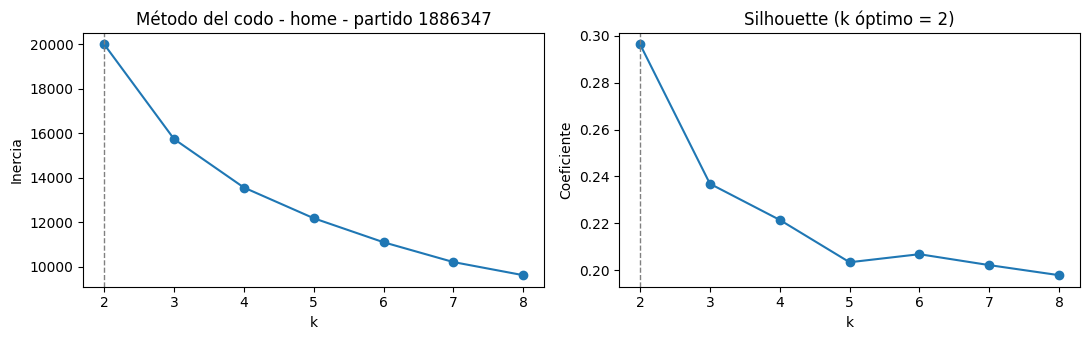

In [22]:
import matplotlib.pyplot as plt

TEAM = 'home'
MATCH_ID = 1886347

res = resultados[TEAM][MATCH_ID]

tabla_k = res['tabla_k']

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))

# ============================================================
# Método del codo
# ============================================================

ax[0].plot(
    tabla_k['k'],
    tabla_k['inercia'],
    'o-'
)

ax[0].set_title(
    f'Método del codo - {TEAM} - partido {MATCH_ID}'
)

ax[0].set_xlabel('k')
ax[0].set_ylabel('Inercia')

ax[0].axvline(
    res['k'],
    color='gray',
    linestyle='--',
    linewidth=1
)


# ============================================================
# Silhouette
# ============================================================

ax[1].plot(
    tabla_k['k'],
    tabla_k['silhouette'],
    'o-'
)

ax[1].axvline(
    res['k'],
    color='gray',
    linestyle='--',
    linewidth=1
)

ax[1].set_title(
    f'Silhouette (k óptimo = {res["k"]})'
)

ax[1].set_xlabel('k')
ax[1].set_ylabel('Coeficiente')


plt.tight_layout()
plt.show()


Misma curva de silhouette que la celda anterior, pero superponiendo los 9 partidos del equipo
local en una sola figura (una línea por partido). Es una primera aproximación visual a la
comparativa entre partidos (apartado 6.2): si la forma de la curva y el *k* óptimo son parecidos
entre partidos, sugiere que la estructura de fases tácticas es consistente para ese equipo a lo
largo de la temporada; si varía mucho de un partido a otro, apunta a que el rival o el contexto
del partido influyen tanto como el estilo propio del equipo.

**Nota de corrección:** la variable que recorre los partidos se llama aquí `partidos_team` (una
lista de IDs), no `partidos`. En una versión anterior de esta celda se reutilizaba el nombre
`partidos`, que ya está en uso en la Sección 5.2 para el diccionario `{match_id: DataFrame}` con
los datos de tracking homogéneos — reutilizar el mismo nombre para una lista de IDs sobrescribía
ese diccionario y podía causar errores confusos si una celda posterior necesitaba volver a acceder
a los datos de tracking por partido.


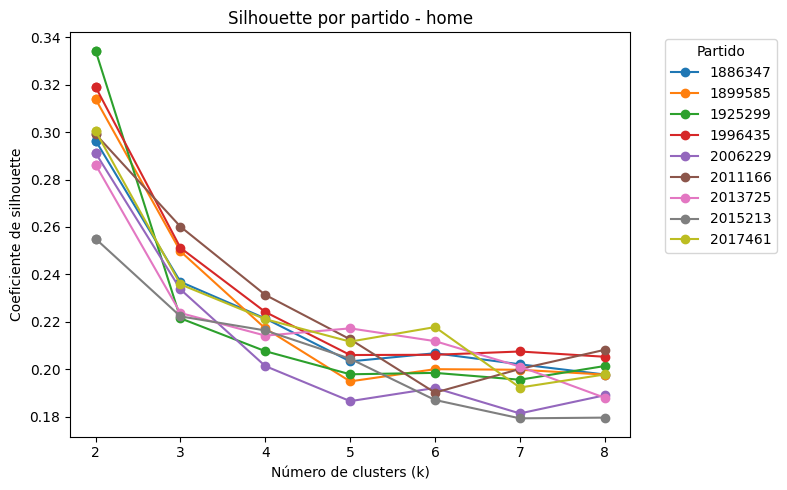

In [23]:
import matplotlib.pyplot as plt

TEAM = 'home'

# CORRECCIÓN: se renombra a 'partidos_team' porque 'partidos' ya se usa
# en la Sección 5.2 como el diccionario {match_id: DataFrame} devuelto por
# la carga de datos; reutilizar ese mismo nombre aquí lo sobrescribiría con
# una lista, lo que podría causar errores confusos si alguna celda posterior
# (o una reejecución parcial del notebook) volviera a necesitar el diccionario
# original.
partidos_team = sorted(
    resultados[TEAM].keys()
)

fig, ax = plt.subplots(
    figsize=(8, 5)
)

for match_id in partidos_team:

    res = resultados[TEAM][match_id]

    tabla_k = res['tabla_k']

    ax.plot(
        tabla_k['k'],
        tabla_k['silhouette'],
        'o-',
        label=str(match_id)
    )

    ax.scatter(
        res['k'],
        tabla_k.loc[
            tabla_k['k'] == res['k'],
            'silhouette'
        ].iloc[0]
    )


ax.set_title(
    f'Silhouette por partido - {TEAM}'
)

ax.set_xlabel('Número de clusters (k)')
ax.set_ylabel('Coeficiente de silhouette')

ax.legend(
    title='Partido',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()


Misma comparación entre los 9 partidos del equipo local, pero con el índice de Davies-Bouldin en
lugar de silhouette (valores más bajos indican clusters mejor separados). Se muestra junto a la
gráfica anterior porque ambos índices deberían ser coherentes entre sí: un mismo partido no
debería aparecer como "muy bueno" en silhouette y "muy malo" en Davies-Bouldin, y si eso ocurriera
convendría revisar ese partido con más detalle antes de confiar en su resultado.


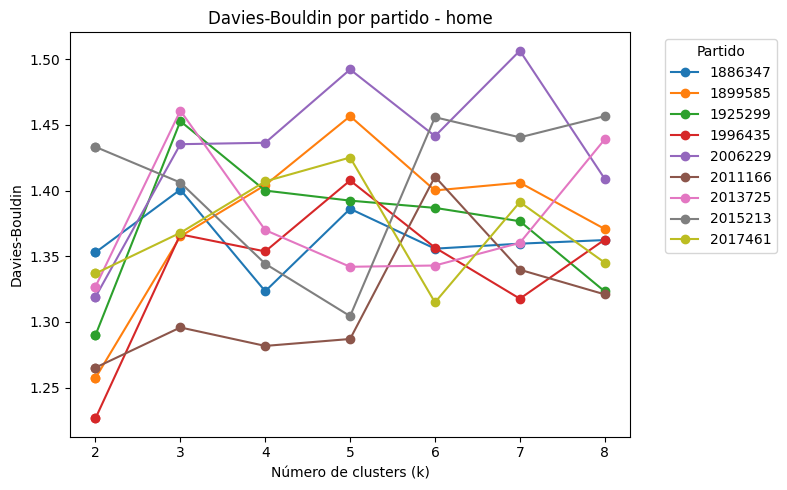

In [24]:
TEAM = 'home'

fig, ax = plt.subplots(
    figsize=(8, 5)
)

for match_id in sorted(resultados[TEAM].keys()):

    res = resultados[TEAM][match_id]

    tabla_k = res['tabla_k']

    ax.plot(
        tabla_k['k'],
        tabla_k['davies_bouldin'],
        'o-',
        label=str(match_id)
    )

    ax.scatter(
        res['k'],
        tabla_k.loc[
            tabla_k['k'] == res['k'],
            'davies_bouldin'
        ].iloc[0]
    )


ax.set_title(
    f'Davies-Bouldin por partido - {TEAM}'
)

ax.set_xlabel('Número de clusters (k)')
ax.set_ylabel('Davies-Bouldin')

ax.legend(
    title='Partido',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()


Línea temporal de la etiqueta de estado (fase táctica), frame a frame, para el partido de ejemplo.
Es la representación más directa de la segmentación temporal ya fusionada: cada escalón horizontal
corresponde a una fase con una duración de al menos `MIN_DURACION_FASE_S` segundos.


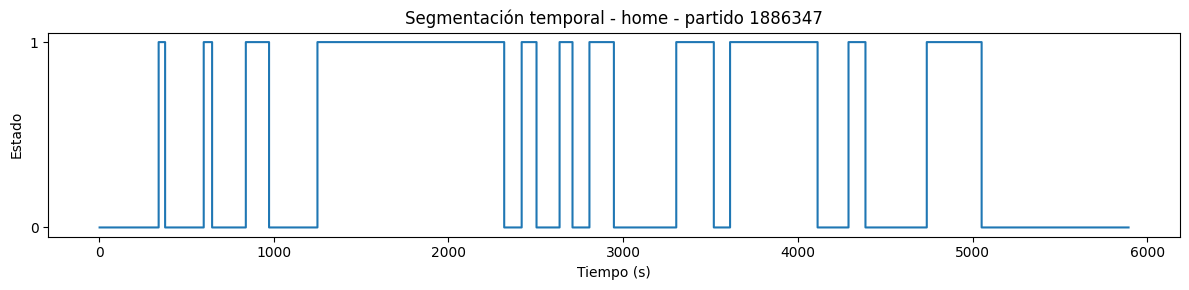

In [25]:
TEAM = 'home'
MATCH_ID = 1886347

res = resultados[TEAM][MATCH_ID]

sub = res['sub']

labels_tmp = res['labels_temporal']

tiempo = (
    sub['frame'].to_numpy()
    / FPS_REFERENCIA
)

fig, ax = plt.subplots(
    figsize=(12, 3)
)

ax.step(
    tiempo,
    labels_tmp,
    where='post'
)

ax.set_title(
    f'Segmentación temporal - {TEAM} - partido {MATCH_ID}'
)

ax.set_xlabel('Tiempo (s)')
ax.set_ylabel('Estado')

ax.set_yticks(
    sorted(np.unique(labels_tmp))
)

plt.tight_layout()
plt.show()


Representación alternativa de la misma información anterior, dibujando cada fase como un segmento
horizontal grueso en lugar de un escalón — más fácil de leer cuando hay muchos cambios de fase en
poco tiempo, aunque contiene exactamente los mismos datos que la celda anterior.


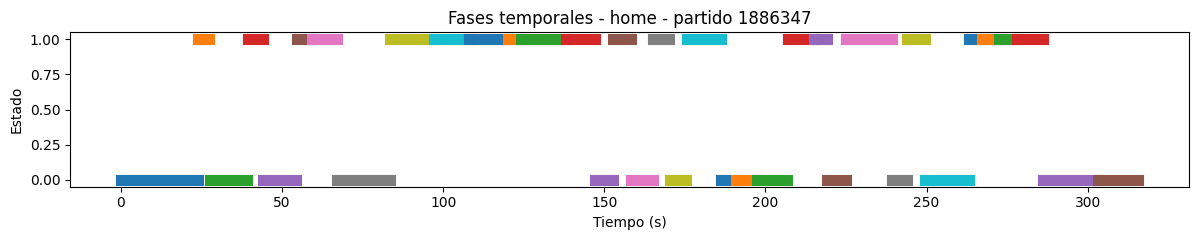

In [26]:
TEAM = 'home'
MATCH_ID = 1886347

res = resultados[TEAM][MATCH_ID]

fases = res['fases']

fig, ax = plt.subplots(
    figsize=(12, 2.5)
)

for _, fase in fases.iterrows():

    inicio = (
        fase['frame_inicio']
        / FPS_REFERENCIA
    )

    fin = (
        fase['frame_fin']
        / FPS_REFERENCIA
    )

    ax.plot(
        [inicio, fin],
        [fase['fase'], fase['fase']],
        linewidth=8
    )

ax.set_title(
    f'Fases temporales - {TEAM} - partido {MATCH_ID}'
)

ax.set_xlabel('Tiempo (s)')
ax.set_ylabel('Estado')

plt.tight_layout()
plt.show()


Tercera variante de la misma línea temporal, esta vez coloreando cada fase con un color distinto
(mapa de color `tab10`) y anotando su etiqueta numérica dentro del propio segmento. Es la versión
más legible de las tres para un partido con muchas fases, y es la que se recomienda usar como
figura definitiva (equivalente a la Figura 5.2 de la memoria) si solo se va a incluir una.


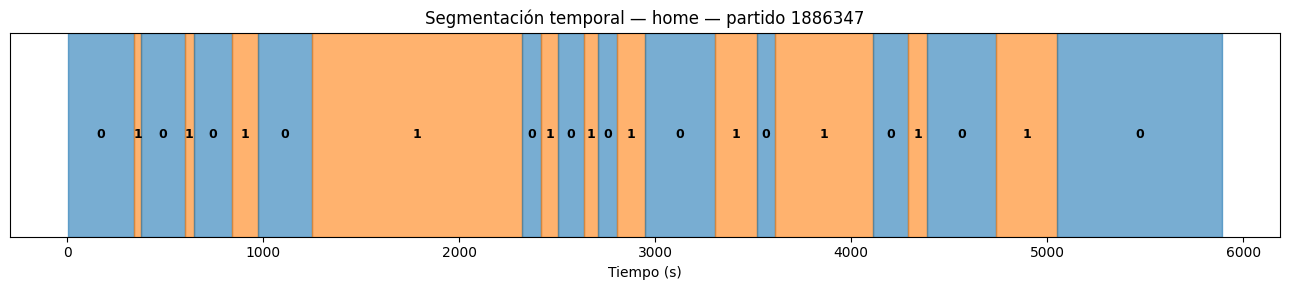

In [27]:
fig, ax = plt.subplots(figsize=(13, 3))

cambios = np.where(np.diff(labels_tmp) != 0)[0] + 1

ini = np.concatenate([[0], cambios])
fin = np.concatenate([cambios, [len(labels_tmp)]])

cmap = plt.get_cmap('tab10')

for a, b in zip(ini, fin):

    b_plot = min(b, len(tiempo) - 1)

    ax.axvspan(
        tiempo[a],
        tiempo[b_plot],
        color=cmap(int(labels_tmp[a]) % 10),
        alpha=0.6
    )

    ax.text(
        (tiempo[a] + tiempo[b_plot]) / 2,
        0.5,
        str(int(labels_tmp[a])),
        ha='center',
        va='center',
        fontsize=9,
        weight='bold'
    )

ax.set_ylim(0, 1)
ax.set_yticks([])
ax.set_xlabel('Tiempo (s)')
ax.set_title(
    f'Segmentación temporal — {TEAM} — partido {MATCH_ID}'
)

plt.tight_layout()
plt.show()


### Estructura espacial por fase

`dibujar_frame()` dibuja sobre el terreno de juego las posiciones de los jugadores de un equipo,
su centroide y el balón, en un frame concreto. Se usa a continuación para mostrar un frame
representativo (el frame central) de cada fase detectada, como comprobación visual de que la
interpretación táctica de cada fase (bloque alto, bloque bajo, etc.) es razonable.

**Corrección aplicada:** la versión original de esta función filtraba el DataFrame `tracking`
solo por `team` y `frame`, sin filtrar también por `match`. Como el `frame_id` de SkillCorner
no es necesariamente único entre partidos distintos (cada partido numera sus propios frames de
forma independiente), esto podía hacer que, para un número de frame que existiera en más de un
partido, la función mezclase o eligiese por accidente jugadores de un partido distinto al que se
estaba analizando. Se ha añadido el parámetro `match_id` a la función y su correspondiente filtro,
igual que ya se hacía correctamente en la celda de la sección "Estructura espacial por fase" más
abajo (la que construye `tracking_partido`).


In [28]:
def dibujar_frame(team, match_id, frame, ax):
    # CORRECCIÓN: el filtro original solo usaba team+frame. El frame_id de
    # SkillCorner no es único entre partidos distintos (cada partido numera
    # sus propios frames), así que sin filtrar también por 'match' esta
    # función podía mezclar jugadores de partidos diferentes que compartieran
    # el mismo número de frame. Ahora se exige coincidencia de 'match' además
    # de 'team' y 'frame', igual que ya se hace más abajo (Sección 5.6) en
    # tracking_partido = tracking[(tracking['match']==MATCH_ID) & ...].

    fr = tracking[
        (tracking['match'] == match_id) &
        (tracking['team'] == team) &
        (tracking['frame'] == frame)
    ]

    bx = tracking[
        (tracking['match'] == match_id) &
        (tracking['team'] == 'ball') &
        (tracking['frame'] == frame)
    ]

    # Jugadores
    ax.scatter(
        fr['x'],
        fr['y'],
        c='tab:blue',
        s=40
    )

    # Centroide
    if len(fr) > 0:
        cx = fr['x'].mean()
        cy = fr['y'].mean()

        ax.scatter(
            cx,
            cy,
            c='red',
            marker='x',
            s=80,
            linewidths=2
        )

    # Balón
    ax.scatter(
        bx['x'],
        bx['y'],
        c='black',
        marker='D',
        s=30
    )

    ax.set_xlim(-53, 53)
    ax.set_ylim(-34, 34)

    ax.axhline(0, color='lightgray', lw=0.5)
    ax.axvline(0, color='lightgray', lw=0.5)

    ax.set_aspect('equal')


Se llama a `dibujar_frame()` una vez por cada estado/fase presente en el partido de ejemplo,
pasando ahora también `MATCH_ID` (definido en la celda de la línea temporal, unas celdas más
arriba) para que la corrección anterior tenga efecto.


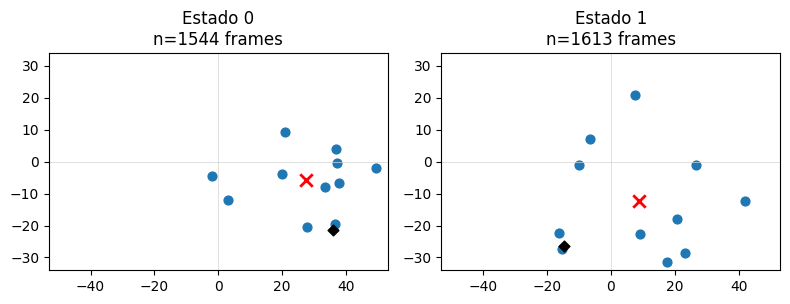

In [29]:
etiquetas_presentes = sorted(
    set(int(l) for l in labels_tmp)
)

fig, axes = plt.subplots(
    1,
    len(etiquetas_presentes),
    figsize=(4 * len(etiquetas_presentes), 4)
)

axes = np.atleast_1d(axes)

for ax, k in zip(axes, etiquetas_presentes):

    fr = sub['frame'].values[labels_tmp == k]

    if len(fr):
        frame_representativo = fr[len(fr) // 2]

        # Se añade MATCH_ID (definido en la celda anterior) para que
        # dibujar_frame filtre el partido correcto, no solo el equipo.
        dibujar_frame(
            TEAM,
            MATCH_ID,
            frame_representativo,
            ax
        )

        ax.set_title(
            f'Estado {k}\n'
            f'n={len(fr)} frames'
        )

plt.tight_layout()
plt.show()


### Duración y número de apariciones de cada fase

Estas tres celdas resumen, para el partido de ejemplo, cuántas veces aparece cada fase a lo largo
del partido (`apariciones`) y cuánto tiempo ocupa en total (`duracion_total_s`) y por aparición
individual (`duracion_s`). Es el equivalente, para un único partido real, de la Tabla 6.1 de la
memoria (que en el capítulo de resultados se construye para el conjunto de los 9 partidos).


In [30]:
TEAM = 'home'
MATCH_ID = 1886347

res = resultados[TEAM][MATCH_ID]
fases = res['fases'].copy()

# Número de apariciones de cada estado
apariciones = (
    fases.groupby('fase')
    .size()
    .rename('apariciones')
)

# Duración total por estado
duracion_total = (
    fases.groupby('fase')['duracion_s']
    .sum()
    .rename('duracion_total_s')
)

duracion_estados = pd.concat(
    [apariciones, duracion_total],
    axis=1
).reset_index()

duracion_estados


,fase,apariciones,duracion_total_s
0,0,15,154.4
1,1,21,161.3


Duración total acumulada de cada estado a lo largo del partido, en segundos — permite ver de un
vistazo qué fase táctica domina el partido (por ejemplo, si el equipo pasa la mayor parte del
tiempo en posesión organizada frente a bloque bajo).


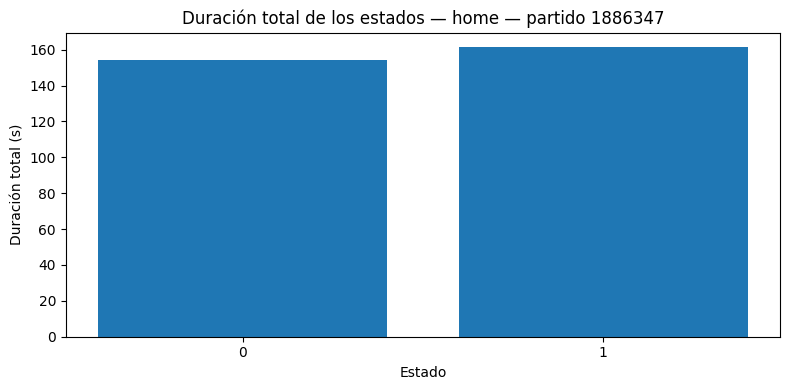

In [31]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    duracion_estados['fase'].astype(str),
    duracion_estados['duracion_total_s']
)

ax.set_xlabel('Estado')
ax.set_ylabel('Duración total (s)')
ax.set_title(
    f'Duración total de los estados — {TEAM} — partido {MATCH_ID}'
)

plt.tight_layout()
plt.show()


Duración de cada aparición individual de cada fase (no el total, sino cada segmento por separado).
Un estado con muchas apariciones cortas y otro con pocas apariciones largas pueden tener la misma
duración total acumulada, pero representan comportamientos tácticos muy distintos (alternancia
frecuente frente a permanencia sostenida); esta gráfica permite distinguir ambos casos.


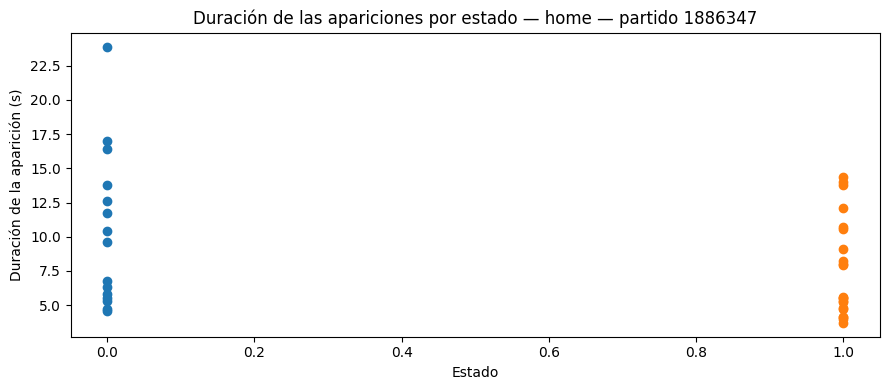

In [32]:
fig, ax = plt.subplots(figsize=(9, 4))

for estado in sorted(fases['fase'].unique()):

    datos = fases.loc[
        fases['fase'] == estado,
        'duracion_s'
    ]

    ax.scatter(
        [estado] * len(datos),
        datos
    )

ax.set_xlabel('Estado')
ax.set_ylabel('Duración de la aparición (s)')
ax.set_title(
    f'Duración de las apariciones por estado — '
    f'{TEAM} — partido {MATCH_ID}'
)

plt.tight_layout()
plt.show()


### Evolución temporal de las variables colectivas

Se vuelven a extraer `sub`, `labels_temporal` y `tiempo` para el partido de ejemplo (por si las
variables en memoria hubieran sido sobrescritas por alguna celda intermedia de otro partido/equipo)
y se comprueba que las tres tienen la misma longitud antes de graficarlas, evitando un error de
dimensiones difícil de diagnosticar si no coincidieran.


In [33]:
TEAM = 'home'
MATCH_ID = 1886347

res = resultados[TEAM][MATCH_ID]

sub = res['sub'].copy()
labels_tmp = res['labels_temporal']

tiempo = sub['frame'].to_numpy() / FPS_REFERENCIA


In [34]:
print(len(sub))
print(len(labels_tmp))
print(len(tiempo))


3157
3157
3157


Evolución del centroide en profundidad (`centroide_x`) a lo largo del partido, con una línea
vertical discontinua en cada cambio de fase detectado. Es la variable más directamente
interpretable: valores altos corresponden a bloque adelantado (presión/bloque alto) y valores
bajos a bloque replegado (bloque bajo), tal como se define en el catálogo de fases del
apartado 4.5.


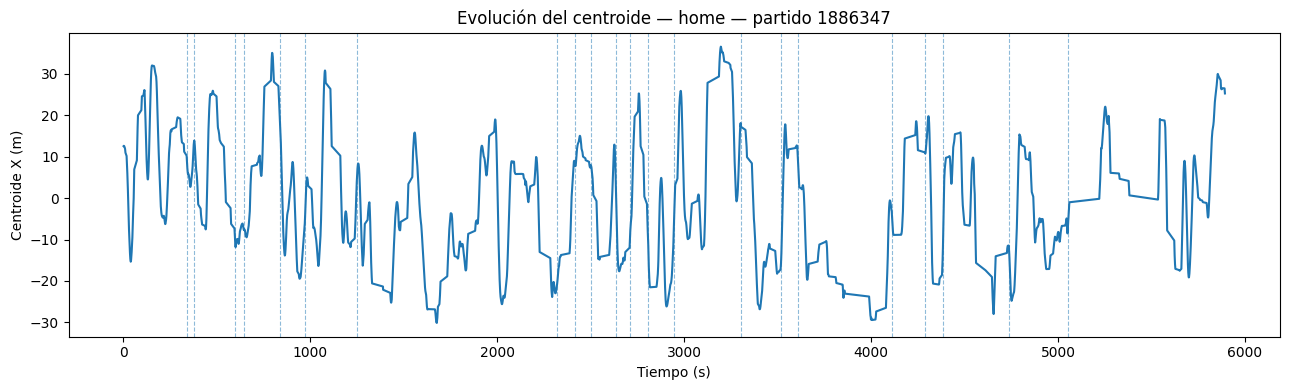

In [35]:
fig, ax = plt.subplots(figsize=(13, 4))

ax.plot(
    tiempo,
    sub['centroide_x']
)

# Cambios de estado
cambios = np.where(
    np.diff(labels_tmp) != 0
)[0] + 1

for c in cambios:
    ax.axvline(
        tiempo[c],
        linestyle='--',
        linewidth=0.8,
        alpha=0.5
    )

ax.set_xlabel('Tiempo (s)')
ax.set_ylabel('Centroide X (m)')
ax.set_title(
    f'Evolución del centroide — {TEAM} — partido {MATCH_ID}'
)

plt.tight_layout()
plt.show()


Misma idea que la celda anterior, pero con la anchura del bloque. Permite comprobar si los cambios
de fase detectados coinciden también con cambios visibles en la anchura (por ejemplo, un equipo
que se estrecha al defender y se ensancha al atacar), o si en este partido concreto la anchura
aporta poca información diferencial frente a la profundidad.


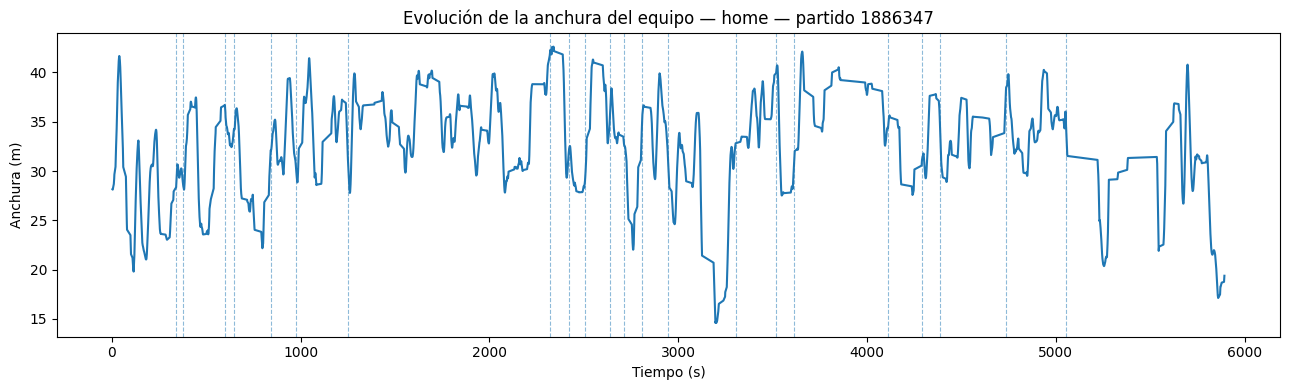

In [36]:
fig, ax = plt.subplots(figsize=(13, 4))

ax.plot(
    tiempo,
    sub['anchura']
)

for c in cambios:
    ax.axvline(
        tiempo[c],
        linestyle='--',
        linewidth=0.8,
        alpha=0.5
    )

ax.set_xlabel('Tiempo (s)')
ax.set_ylabel('Anchura (m)')
ax.set_title(
    f'Evolución de la anchura del equipo — '
    f'{TEAM} — partido {MATCH_ID}'
)

plt.tight_layout()
plt.show()


Misma idea, con la profundidad total del bloque (distancia entre la línea más retrasada y la más
adelantada). Junto con las dos gráficas anteriores, permite hacerse una idea visual de qué
variable o combinación de variables está impulsando realmente cada cambio de fase detectado por el
modelo, antes de dar por sentada la interpretación táctica de la Sección 6.1.


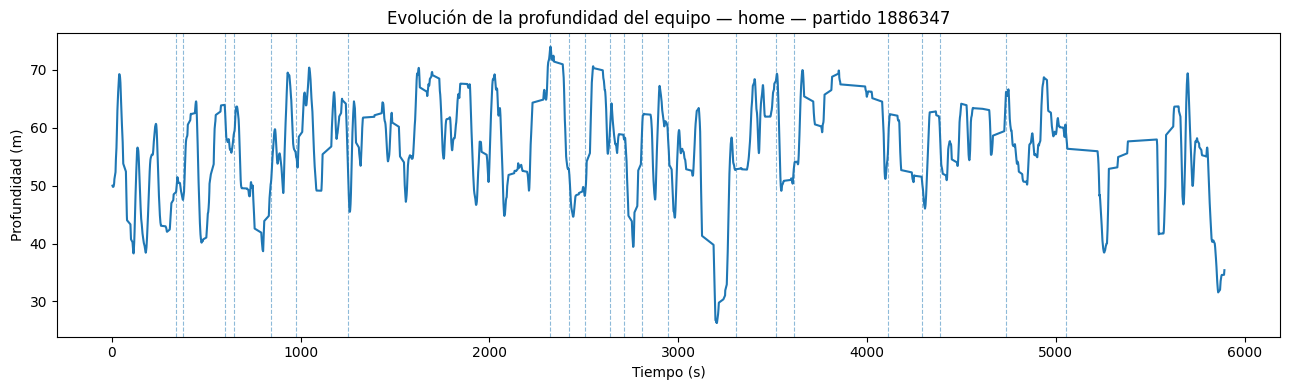

In [37]:
fig, ax = plt.subplots(figsize=(13, 4))

ax.plot(
    tiempo,
    sub['profundidad']
)

for c in cambios:
    ax.axvline(
        tiempo[c],
        linestyle='--',
        linewidth=0.8,
        alpha=0.5
    )

ax.set_xlabel('Tiempo (s)')
ax.set_ylabel('Profundidad (m)')
ax.set_title(
    f'Evolución de la profundidad del equipo — '
    f'{TEAM} — partido {MATCH_ID}'
)

plt.tight_layout()
plt.show()


### Estructura espacial agregada por fase (versión definitiva)

A diferencia de `dibujar_frame()` (que muestra un único frame representativo por fase), esta
celda agrega **todos** los frames de cada fase en una nube de puntos, lo que da una idea más
robusta de la variabilidad espacial dentro de cada estado, no solo de un instante concreto. Esta
celda ya filtraba correctamente `tracking` tanto por `match` como por `team` en la versión
original (`tracking[(tracking['match']==MATCH_ID) & (tracking['team']==TEAM)]`), por lo que no ha
sido necesario corregirla — es, de hecho, el patrón correcto que se ha replicado al arreglar
`dibujar_frame()` más arriba.


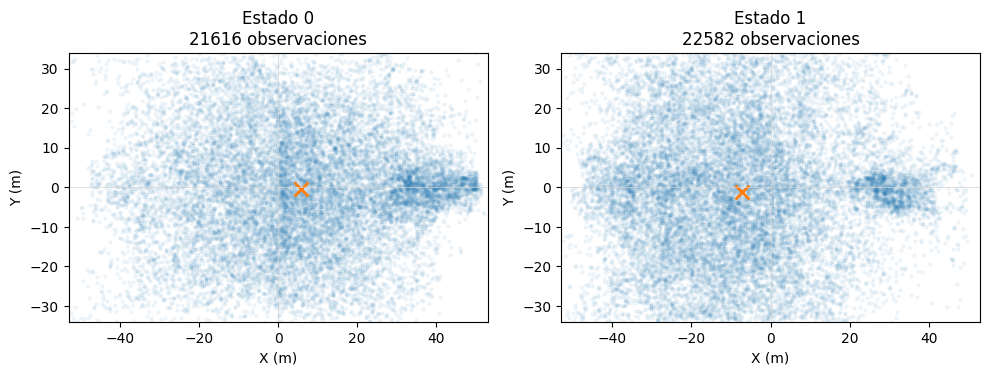

In [38]:
TEAM = 'home'
MATCH_ID = 1886347

res = resultados[TEAM][MATCH_ID]

sub = res['sub'].copy()
labels_tmp = res['labels_temporal']

sub['estado'] = labels_tmp

tracking_partido = tracking[
    (tracking['match'] == MATCH_ID) &
    (tracking['team'] == TEAM)
].copy()

estado_por_frame = (
    sub[['frame', 'estado']]
    .drop_duplicates('frame')
)

tracking_partido = tracking_partido.merge(
    estado_por_frame,
    on='frame',
    how='inner'
)

estados = sorted(
    tracking_partido['estado'].unique()
)

fig, axes = plt.subplots(
    1,
    len(estados),
    figsize=(5 * len(estados), 5)
)

axes = np.atleast_1d(axes)

for ax, estado in zip(axes, estados):

    datos = tracking_partido[
        tracking_partido['estado'] == estado
    ]

    # Nube de posiciones de los jugadores
    ax.scatter(
        datos['x'],
        datos['y'],
        s=5,
        alpha=0.05
    )

    # Centroide medio del estado
    cx = datos['x'].mean()
    cy = datos['y'].mean()

    ax.scatter(
        cx,
        cy,
        marker='x',
        s=100,
        linewidths=2
    )

    ax.set_xlim(-53, 53)
    ax.set_ylim(-34, 34)

    ax.axhline(
        0,
        color='lightgray',
        linewidth=0.5
    )

    ax.axvline(
        0,
        color='lightgray',
        linewidth=0.5
    )

    ax.set_aspect('equal')

    ax.set_title(
        f'Estado {estado}\n'
        f'{len(datos)} observaciones'
    )

    ax.set_xlabel('X (m)')
    ax.set_ylabel('Y (m)')

plt.tight_layout()
plt.show()


## 5.7 Análisis avanzado: modelo PC-HMM (HMM jerárquico condicionado por la posesión)

### Por qué hace falta un segundo modelo

El modelo de las secciones 5.4-5.6 (K-means + HMM, ajustado por separado en cada partido y equipo) converge siempre a **dos estados**. Revisando el código y sus resultados aparecen cuatro limitaciones que explican buena parte de ese resultado:

1. **No sabe quién tiene el balón.** Atacar y defender con el bloque a la misma altura produce vectores de variables parecidos, así que el modelo no puede separar fases que para un entrenador son opuestas.
2. **La escala temporal real es diez veces mayor de la prevista.** Con `sample_rate=1/FPS_REFERENCIA` se conserva 1 frame por segundo, pero el código calcula como si hubiera 10: la ventana de suavizado cubre ~21 s y la duración mínima de fase ~30 s. Las transiciones, que duran pocos segundos, desaparecen.
3. **La orientación no está fijada entre partidos.** El signo de `x` se invierte en el segundo periodo, pero el sentido de ataque de cada equipo depende del campo en que empezó. En el partido 1886347 el local ataca hacia `x < 0`, y en otros al revés. Además `anchura` se calcula sobre `x` en lugar de `y`.
4. **Un modelo por partido.** Cada modelo numera sus estados a su manera, así que el "estado 0" de un partido no tiene por qué significar lo mismo en otro, y no se pueden comparar equipos.

### Qué hace el nuevo modelo

El **PC-HMM** (*Possession-Conditioned Hidden Markov Model*) es un diseño propio, pensado para corregir esas cuatro limitaciones y producir fases con nombre futbolístico. Tiene dos niveles:

**Nivel 1: contexto de juego (reglas explícitas, sin aprendizaje).** Para cada equipo y cada instante se decide primero en qué contexto está, a partir de la posesión que registra SkillCorner (`ball_owning_team_id`):

| Contexto | Regla |
|---|---|
| Balón disputado | la posesión dura menos de `D_DISPUTA_S` = 3 s (el balón cambia de dueño una y otra vez) |
| Transición ofensiva | primeros `T_TRANSICION_S` = 5 s tras recuperar el balón en juego |
| Transición defensiva | primeros 5 s tras perderlo en juego |
| Ataque organizado | el equipo tiene el balón y han pasado más de 5 s desde la recuperación |
| Defensa organizada | el rival tiene el balón y han pasado más de 5 s desde la pérdida |

Las reanudaciones tras balón muerto (saques, faltas) no cuentan como transición, porque el equipo ha tenido tiempo de colocarse. Los cambios de posesión de menos de 1 s se consideran ruido del registro.

**Nivel 2: sub-fases dentro de ataque y defensa (aprendizaje no supervisado).** Dentro de *Ataque organizado* y de *Defensa organizada* se ajusta un **HMM gaussiano compartido por los 18 equipos-partido**, con estas mejoras:

- Datos a **2 Hz** con la escala temporal correcta (suavizado de 3 s, duración mínima de sub-fase de 4 s).
- **Coordenadas en la perspectiva del equipo**: se gira el campo 180° cuando hace falta para que cada equipo defienda siempre la portería de `x = -52,5` y ataque hacia `x > 0`. El lado de la portería propia se detecta con la posición mediana del portero en cada periodo.
- **Variables corregidas**, calculadas con los 10 jugadores de campo (sin portero): altura del bloque (`centroide_x`), anchura real (sobre `y`), longitud, superficie, posición del balón (`balon_x`) y distancia del bloque al balón.
- **Número de sub-fases elegido por BIC** (k entre 2 y 5), un criterio pensado para modelos probabilísticos que penaliza la complejidad, en lugar del silhouette. Se descartan las soluciones con algún estado que ocupe menos del 3 % del tiempo.
- **HMM "pegajoso" (sticky HMM).** Se añade un prior de Dirichlet sobre la matriz de transición que favorece permanecer en el mismo estado (Fox et al., 2011). Sin él, al trabajar a 2 Hz el algoritmo EM tiende a aprender dos estados gemelos con la misma media que se alternan frame a frame, un resultado sin sentido táctico.
- **Nombres automáticos y estables**, con reglas fijas. En defensa, los estados se ordenan por la altura media del bloque (de *bloque muy bajo* a *presión muy alta*). En ataque, el estado con el balón más retrasado es la *salida de balón* y el del balón más adelantado, la *finalización*; los intermedios se distinguen por la anchura del equipo (*progresión por dentro* el más estrecho, *progresión en amplitud* el más ancho y *construcción* el intermedio). Como el modelo es compartido, una etiqueta significa lo mismo en todos los partidos.

El resultado es un catálogo de fases con nombre (por ejemplo, *Defensa: bloque alto*, *Transición ofensiva*, *Ataque: progresión*), muy cercano al catálogo que se planteó al principio del TFM (apartado 4.2).

In [39]:
# ============================================================
# 5.7.1 Configuración y carga de los partidos a 2 Hz
# ============================================================
import numpy as np
import pandas as pd
from scipy.spatial import ConvexHull
from kloppy import skillcorner

FPS_NATIVO = 10            # frecuencia nativa de SkillCorner (metadata.frame_rate)
HZ_AV = 2                  # frecuencia efectiva del nuevo análisis
SAMPLE_RATE_AV = HZ_AV / FPS_NATIVO   # 0.2 -> se conserva 1 de cada 5 frames
VENTANA_AV_S = 3           # suavizado de las variables colectivas (segundos reales)
DEBOUNCE_S = 1             # cambios de posesión más cortos se consideran ruido del registro
D_DISPUTA_S = 3            # posesiones más cortas = balón disputado
T_TRANSICION_S = 5         # segundos tras recuperar o perder el balón que cuentan como transición
MIN_FASE_AV_S = 4          # duración mínima de una sub-fase
K_RANGO_AV = range(2, 6)   # sub-fases a explorar por BIC dentro de ataque y de defensa
STICKY = 0.05              # fuerza del prior de permanencia del HMM (fracción de frames por estado)
OCUPACION_MIN = 0.03       # un estado debe ocupar al menos el 3 % del contexto para ser válido

datos_av = {}
for mid in MATCH_IDS:
    ds_av = skillcorner.load_open_data(match_id=mid, sample_rate=SAMPLE_RATE_AV,
                                       coordinates='skillcorner', only_alive=True)
    datos_av[mid] = (ds_av, ds_av.to_df())
    print(f'[{mid}] {len(datos_av[mid][1])} frames a {HZ_AV} Hz')

[1886347] 6301 frames a 2 Hz


[1899585] 5765 frames a 2 Hz


[1925299] 7016 frames a 2 Hz


[1996435] 6391 frames a 2 Hz


[2006229] 6377 frames a 2 Hz


[2011166] 5437 frames a 2 Hz


[2013725] 6174 frames a 2 Hz


[2015213] 6166 frames a 2 Hz


[2017461] 5590 frames a 2 Hz


### 5.7.2 Perspectiva del equipo y variables corregidas

Para cada partido y equipo se construye una tabla con una fila por instante. Tres detalles importan:

- **Portero fuera del bloque.** El portero se identifica por su posición inicial en los metadatos (`starting_position`) y se excluye del cálculo del centroide, la anchura, la longitud y la superficie. Así la longitud mide el bloque de campo y no la distancia al portero.
- **Giro del campo.** En cada periodo se mira la mediana de `x` del portero: si está en `x > 0`, se giran todas las coordenadas 180° (`x → -x`, `y → -y`). Tras el giro, el equipo analizado siempre defiende la portería de la izquierda, de modo que un `centroide_x` alto significa siempre bloque adelantado.
- **Escala temporal real.** El reloj (`timestamp`) se usa para calcular velocidades en m/s y detectar los saltos de balón muerto (huecos de más de 1 s entre frames conservados).

In [40]:
# ============================================================
# 5.7.2 Perspectiva del equipo y variables corregidas
# ============================================================
def es_portero(player):
    return 'Goalkeeper' in str(player.starting_position)

def construir_perspectiva(ds, df, match_id):
    t = df['timestamp'].dt.total_seconds().to_numpy()
    periodo = df['period_id'].to_numpy()
    owner = df['ball_owning_team_id'].to_numpy()
    bx, by = df['ball_x'].to_numpy(float), df['ball_y'].to_numpy(float)
    equipos = list(ds.metadata.teams)
    salida = []
    for eq in equipos:
        rival = [e for e in equipos if e is not eq][0]
        def coords(team, portero):
            ids = [str(p.player_id) for p in team.players
                   if es_portero(p) == portero and f'{p.player_id}_x' in df.columns]
            if not ids:
                return np.full((len(df), 0), np.nan), np.full((len(df), 0), np.nan)
            return (df[[f'{i}_x' for i in ids]].to_numpy(float),
                    df[[f'{i}_y' for i in ids]].to_numpy(float))
        Xc, Yc = coords(eq, False)       # jugadores de campo
        Xg, _ = coords(eq, True)         # portero
        Xr, _ = coords(rival, False)     # jugadores de campo del rival
        # Giro de 180 grados en los periodos en que la portería propia está en x > 0
        signo = np.ones(len(df))
        for p in np.unique(periodo):
            m = periodo == p
            ref = Xg[m] if Xg.size and np.isfinite(Xg[m]).any() else Xc[m]
            if np.nanmedian(ref) > 0:
                signo[m] = -1.0
        s = signo[:, None]
        Xc, Yc, Xr = Xc * s, Yc * s, Xr * s
        bxs, bys = bx * signo, by * signo
        cx, cy = np.nanmean(Xc, axis=1), np.nanmean(Yc, axis=1)
        area = np.full(len(df), np.nan)
        for i in range(len(df)):
            v = np.isfinite(Xc[i]) & np.isfinite(Yc[i])
            if v.sum() >= 3:
                try:
                    area[i] = ConvexHull(np.c_[Xc[i][v], Yc[i][v]]).volume
                except Exception:
                    pass
        salida.append(pd.DataFrame({
            'match': match_id, 'team': str(eq.ground).lower(), 'team_id': eq.team_id,
            'frame': df['frame_id'].to_numpy(), 'periodo': periodo, 't': t,
            'centroide_x': cx, 'centroide_y': cy,
            'anchura': 2 * np.nanstd(Yc, axis=1),                          # eje y (lateral)
            'longitud': np.nanmax(Xc, axis=1) - np.nanmin(Xc, axis=1),     # sin portero
            'superficie': area,
            'balon_x': bxs, 'dist_balon': np.hypot(cx - bxs, cy - bys),
            'rival_centroide_x': np.nanmean(Xr, axis=1),
            'posesion_raw': (owner == eq.team_id).astype(int)}))
    return salida

bloques = []
for mid, (ds_av, df_av) in datos_av.items():
    bloques += construir_perspectiva(ds_av, df_av, mid)
av = (pd.concat(bloques, ignore_index=True)
        .sort_values(['match', 'team', 'frame']).reset_index(drop=True))

VARS_AV = ['centroide_x', 'anchura', 'longitud', 'superficie', 'balon_x', 'dist_balon', 'rival_centroide_x']
w_suav = int(VENTANA_AV_S * HZ_AV)
av[VARS_AV] = (av.groupby(['match', 'team', 'periodo'], sort=False)[VARS_AV]
                 .transform(lambda x: x.rolling(w_suav, center=True, min_periods=1).mean()))
dt = av.groupby(['match', 'team', 'periodo'])['t'].diff()
av['vel_centroide_x'] = av.groupby(['match', 'team', 'periodo'])['centroide_x'].diff() / dt
av.loc[dt > 1.0, 'vel_centroide_x'] = np.nan
av = av.dropna(subset=['centroide_x', 'anchura', 'longitud', 'superficie', 'balon_x']).reset_index(drop=True)

print('Filas equipo-instante (2 Hz):', len(av))
print('\nComprobación del giro: posición media del bloque (debe ser parecida para local y visitante)')
print(av.groupby('team')[['centroide_x', 'anchura', 'longitud']].mean().round(1))

Filas equipo-instante (2 Hz): 110434

Comprobación del giro: posición media del bloque (debe ser parecida para local y visitante)
      centroide_x  anchura  longitud
team                                
away         -5.3     24.3      31.4
home         -0.6     24.4      32.4


### 5.7.3 Nivel 1: contexto de juego

La función `contexto_de_juego()` aplica las reglas de la tabla anterior. Primero limpia la posesión (los cambios de menos de `DEBOUNCE_S` se ignoran). Después recorre cada tramo de posesión y calcula su duración total, el tiempo transcurrido desde que empezó y si empezó tras balón muerto. Con esos tres datos asigna el contexto.

In [41]:
# ============================================================
# 5.7.3 Nivel 1: contexto de juego a partir de la posesión
# ============================================================
def contexto_de_juego(g):
    p = g['posesion_raw'].to_numpy().copy()
    per = g['periodo'].to_numpy()
    t = g['t'].to_numpy()
    n = len(p)

    def tramos(v):
        out, ini = [], 0
        for i in range(1, n + 1):
            if i == n or v[i] != v[ini] or per[i] != per[ini]:
                out.append((ini, i)); ini = i
        return out

    # 1) Limpieza: cambios de posesión de menos de DEBOUNCE_S = ruido del registro
    tr = tramos(p)
    for k in range(1, len(tr)):
        a, b = tr[k]
        if (t[b - 1] - t[a] + 1 / HZ_AV) < DEBOUNCE_S and per[a] == per[tr[k - 1][0]]:
            p[a:b] = p[tr[k - 1][0]]

    # 2) Balón muerto: hueco de más de 1 s entre frames conservados o cambio de periodo
    reanudacion = np.r_[True, (np.diff(t) > 1.0) | (per[1:] != per[:-1])]

    ctx = np.empty(n, dtype=object)
    for a, b in tramos(p):
        duracion = t[b - 1] - t[a] + 1 / HZ_AV
        transcurrido = t[a:b] - t[a]
        tras_balon_muerto = reanudacion[max(0, a - 2 * HZ_AV):a + 1].any()
        con_balon = p[a] == 1
        if duracion < D_DISPUTA_S:
            ctx[a:b] = 'Balón disputado'
        else:
            organizado = 'Ataque' if con_balon else 'Defensa'
            transicion = 'Transición ofensiva' if con_balon else 'Transición defensiva'
            es_trans = (transcurrido <= T_TRANSICION_S) & (not tras_balon_muerto)
            ctx[a:b] = np.where(es_trans, transicion, organizado)
    return pd.Series(ctx, index=g.index), pd.Series(p, index=g.index)

ctxs, poss = [], []
for _, g in av.groupby(['match', 'team'], sort=False):
    c, p = contexto_de_juego(g)
    ctxs.append(c); poss.append(p)
av['contexto'] = pd.concat(ctxs)
av['posesion'] = pd.concat(poss)
print('Reparto del tiempo por contexto (%):')
print((av['contexto'].value_counts(normalize=True) * 100).round(1))

Reparto del tiempo por contexto (%):
contexto
Ataque                  37.3
Defensa                 37.3
Transición defensiva    11.5
Transición ofensiva     11.5
Balón disputado          2.3
Name: proportion, dtype: float64


### 5.7.4 Nivel 2: sub-fases con un HMM compartido

Dentro de *Ataque* y de *Defensa* se ajusta un HMM gaussiano con covarianza completa sobre seis variables estandarizadas: `centroide_x`, `anchura`, `longitud`, `superficie`, `balon_x` y `dist_balon`. El modelo se entrena con **todos los tramos de los 18 equipos-partido a la vez** (cada tramo contiguo es una secuencia independiente para el HMM), de modo que cada estado aprendido es el mismo en todos los partidos.

El número de estados se elige con el **criterio BIC** (*Bayesian Information Criterion*): `BIC = -2·log-verosimilitud + nº de parámetros · log(n)`. Se queda el k con menor BIC. A diferencia del silhouette, el BIC evalúa el modelo completo (incluidas las transiciones entre estados) y castiga añadir estados que no mejoran lo suficiente el ajuste.

Por último, `nombrar_estados()` pone nombre a cada estado con las reglas descritas al principio de la sección. `fusionar_cortos()` elimina tramos de menos de `MIN_FASE_AV_S` segundos, igual que `extraer_fases()` en la sección 5.4.

In [42]:
# ============================================================
# 5.7.4 Nivel 2: HMM compartido dentro de ataque y defensa
# ============================================================
from hmmlearn.hmm import GaussianHMM
from sklearn.preprocessing import StandardScaler

VARS_NIVEL2 = ['centroide_x', 'anchura', 'longitud', 'superficie', 'balon_x', 'dist_balon']

NOMBRES_DEFENSA = {2: ['Bloque bajo', 'Bloque alto'],
                   3: ['Bloque bajo', 'Bloque medio', 'Bloque alto'],
                   4: ['Bloque bajo', 'Bloque medio-bajo', 'Bloque medio-alto', 'Bloque alto'],
                   5: ['Bloque muy bajo', 'Bloque bajo', 'Bloque medio', 'Bloque alto', 'Presión muy alta']}
NOMBRES_ATAQUE_CENTRO = {1: ['Progresión'],
                         2: ['Progresión por dentro', 'Progresión en amplitud'],
                         3: ['Progresión por dentro', 'Construcción', 'Progresión en amplitud']}
VAR_ORDEN = {'Defensa': 'centroide_x', 'Ataque': 'balon_x'}

def secuencias(df_ctx):
    """Índices y longitudes de los tramos contiguos (una secuencia por tramo)."""
    idx, lens = [], []
    for _, g in df_ctx.groupby(['match', 'team'], sort=False):
        f = g.index.to_numpy()
        for tramo in np.split(f, np.flatnonzero(np.diff(f) != 1) + 1):
            idx.append(tramo); lens.append(len(tramo))
    return np.concatenate(idx), lens

def hmm_pegajoso(k, n, seed=SEMILLA):
    """HMM gaussiano con prior de Dirichlet que favorece quedarse en el mismo estado
    (sticky HMM, Fox et al., 2011). Sin él, el EM puede aprender dos estados gemelos
    que se alternan frame a frame."""
    prior = np.ones((k, k)) + np.eye(k) * STICKY * n / k
    return GaussianHMM(n_components=k, covariance_type='full', n_iter=100,
                       random_state=seed, transmat_prior=prior)

def bic_hmm(model, X, lens):
    k, d = model.n_components, X.shape[1]
    n_par = (k - 1) + k * (k - 1) + k * d + k * d * (d + 1) / 2
    return -2 * model.score(X, lens) + n_par * np.log(len(X))

def ajustar_nivel2(df_train, ctx, k_rango=K_RANGO_AV, seed=SEMILLA):
    idx, lens = secuencias(df_train[df_train['contexto'] == ctx])
    esc = StandardScaler().fit(df_train.loc[idx, VARS_NIVEL2])
    X = esc.transform(df_train.loc[idx, VARS_NIVEL2])
    candidatos = []
    for k in k_rango:
        hmm = hmm_pegajoso(k, len(X), seed).fit(X, lens)
        ocup = np.bincount(hmm.predict(X, lens), minlength=k) / len(X)
        candidatos.append({'k': k, 'BIC': bic_hmm(hmm, X, lens), 'ocupación mínima': ocup.min(),
                           'válido': ocup.min() >= OCUPACION_MIN, 'modelo': hmm})
    validos = [c for c in candidatos if c['válido']] or candidatos
    mejor = min(validos, key=lambda c: c['BIC'])
    tabla = pd.DataFrame([{k: v for k, v in c.items() if k != 'modelo'} for c in candidatos])
    return mejor['modelo'], esc, tabla

def nombrar_estados(hmm, esc, ctx):
    """Reglas de nombre, deterministas:
    - Defensa: estados ordenados por altura media del bloque (centroide_x).
    - Ataque: el estado con el balón más retrasado es la salida de balón y el del balón
      más adelantado, la finalización; los intermedios se ordenan por anchura
      (el más estrecho, progresión por dentro; el más ancho, progresión en amplitud)."""
    medias = pd.DataFrame(esc.inverse_transform(hmm.means_), columns=VARS_NIVEL2)
    k = hmm.n_components
    if ctx == 'Defensa':
        orden = medias['centroide_x'].argsort().to_numpy()
        return {int(e): NOMBRES_DEFENSA[k][r] for r, e in enumerate(orden)}
    orden = medias['balon_x'].argsort().to_numpy()
    nombres = {int(orden[0]): 'Salida de balón', int(orden[-1]): 'Finalización'}
    centro = [int(e) for e in orden[1:-1]]
    if centro:
        por_anchura = sorted(centro, key=lambda e: medias.loc[e, 'anchura'])
        for e, n in zip(por_anchura, NOMBRES_ATAQUE_CENTRO[len(centro)]):
            nombres[e] = n
    return nombres

def orden_fases(modelos):
    """Orden de presentación: defensa (de bloque bajo a alto), transiciones y ataque."""
    out = []
    for ctx, var in [('Defensa', 'centroide_x'), ('Ataque', 'balon_x')]:
        hmm, esc, nombres = modelos[ctx]
        medias = pd.DataFrame(esc.inverse_transform(hmm.means_), columns=VARS_NIVEL2)[var]
        fases = [f'{ctx}: {nombres[int(e)]}' for e in medias.argsort().to_numpy()]
        out += fases if ctx == 'Defensa' else ['Transición defensiva', 'Balón disputado', 'Transición ofensiva'] + fases
    return out

def fusionar_cortos(labels, min_len):
    labels = np.asarray(labels, dtype=object).copy()
    while True:
        ini = [0] + [i for i in range(1, len(labels)) if labels[i] != labels[i - 1]]
        fin = ini[1:] + [len(labels)]
        cortos = [j for j, (a, b) in enumerate(zip(ini, fin)) if b - a < min_len]
        if not cortos or len(ini) == 1:
            return labels
        j = cortos[0]
        izq = fin[j - 1] - ini[j - 1] if j > 0 else -1
        der = fin[j + 1] - ini[j + 1] if j + 1 < len(ini) else -1
        labels[ini[j]:fin[j]] = labels[ini[j - 1]] if izq >= der else labels[ini[j + 1]]

def entrenar_pc_hmm(df_train, k_fijo=None):
    """k_fijo: dict opcional {contexto: k} para no repetir la búsqueda por BIC."""
    modelos, tablas = {}, {}
    for ctx in ['Defensa', 'Ataque']:
        rango = [k_fijo[ctx]] if k_fijo else K_RANGO_AV
        hmm, esc, tabla = ajustar_nivel2(df_train, ctx, k_rango=rango)
        modelos[ctx] = (hmm, esc, nombrar_estados(hmm, esc, ctx))
        tablas[ctx] = tabla
    return modelos, tablas

def aplicar_pc_hmm(df_obj, modelos):
    etiqueta = df_obj['contexto'].to_numpy(dtype=object).copy()
    for ctx, (hmm, esc, nombres) in modelos.items():
        sub = df_obj[df_obj['contexto'] == ctx]
        if len(sub) == 0:
            continue
        idx, lens = secuencias(sub)
        est = hmm.predict(esc.transform(df_obj.loc[idx, VARS_NIVEL2]), lens)
        etiqueta[df_obj.index.get_indexer(idx)] = [f'{ctx}: {nombres[int(e)]}' for e in est]
    out = pd.Series(etiqueta, index=df_obj.index)
    for _, g in df_obj.groupby(['match', 'team'], sort=False):
        out.loc[g.index] = fusionar_cortos(out.loc[g.index].to_numpy(), int(MIN_FASE_AV_S * HZ_AV))
    return out

modelos_av, tablas_bic = entrenar_pc_hmm(av)
for ctx, tabla in tablas_bic.items():
    k = modelos_av[ctx][0].n_components
    print(f'\n{ctx}: sub-fases elegidas por BIC = {k}')
    print(tabla.assign(BIC=tabla['BIC'].round(0), **{'ocupación mínima': tabla['ocupación mínima'].round(3)}).to_string(index=False))
av['fase_av'] = aplicar_pc_hmm(av, modelos_av)


Defensa: sub-fases elegidas por BIC = 5
 k      BIC  ocupación mínima  válido
 2 396164.0             0.492    True
 3 357483.0             0.280    True
 4 321988.0             0.211    True
 5 303242.0             0.150    True

Ataque: sub-fases elegidas por BIC = 5
 k      BIC  ocupación mínima  válido
 2 412221.0             0.497    True
 3 375767.0             0.289    True
 4 344098.0             0.205    True
 5 330617.0             0.124    True


### 5.7.5 Perfil de cada fase

La tabla siguiente describe cada fase con la media de sus variables (en la perspectiva del equipo: `x < 0` es el propio campo) y el porcentaje del tiempo de juego vivo que ocupa. Es la tabla que permite comprobar que los nombres tienen sentido: por ejemplo, el *bloque bajo* debe tener el centroide más retrasado y la superficie más pequeña, y la *finalización* el balón más cerca de la portería rival.

In [43]:
# ============================================================
# 5.7.5 Perfil de cada fase detectada por el PC-HMM
# ============================================================
ORDEN_FASES = orden_fases(modelos_av)
ORDEN_FASES = [f for f in ORDEN_FASES if f in set(av['fase_av'])]

perfil = (av.groupby('fase_av')[['centroide_x', 'anchura', 'longitud', 'superficie',
                                  'balon_x', 'dist_balon', 'vel_centroide_x']].mean())
perfil['% tiempo'] = av['fase_av'].value_counts(normalize=True) * 100
perfil = perfil.loc[ORDEN_FASES].round(1)
perfil.columns = ['Altura bloque (m)', 'Anchura (m)', 'Longitud (m)', 'Superficie (m²)',
                  'Balón x (m)', 'Dist. al balón (m)', 'Vel. bloque (m/s)', '% tiempo']
perfil

,Altura bloque (m),Anchura (m),Longitud (m),Superficie (m²),Balón x (m),Dist. al balón (m),Vel. bloque (m/s),% tiempo
fase_av,,,,,,,,
Defensa: Bloque muy bajo,-28.5,19.7,21.3,439.2,-23.7,15.8,0.0,8.3
Defensa: Bloque bajo,-18.7,20.6,36.4,788.1,-25.4,15.9,-1.7,6.5
Defensa: Bloque medio,-5.8,23.2,25.5,684.9,12.0,21.7,0.4,8.7
Defensa: Bloque alto,-0.2,21.2,29.1,683.4,4.7,14.5,-0.8,7.7
Defensa: Presión muy alta,12.8,23.1,37.3,975.1,31.0,23.0,0.2,5.6
Transición defensiva,-2.1,22.7,32.1,806.0,4.9,17.5,-0.3,12.9
Balón disputado,-2.9,22.2,32.0,769.4,-0.4,14.9,-0.1,0.6
Transición ofensiva,-4.0,24.2,33.5,902.2,-5.1,16.3,0.2,13.0
Ataque: Salida de balón,-3.7,33.3,35.8,1363.5,-17.7,19.1,-0.4,10.2


### 5.7.6 Visualización del PC-HMM

Tres vistas: la línea temporal de fases del partido de ejemplo, el perfil de cada fase normalizado (qué variables la distinguen) y el reparto del tiempo por fase de cada equipo, que es la vista más útil para un cuerpo técnico. Los colores siguen una lógica fija: azules para las fases defensivas (más oscuro cuanto más alto el bloque), naranjas para las ofensivas (más oscuro cuanto más cerca de la portería rival) y colores propios para transiciones y balón disputado.

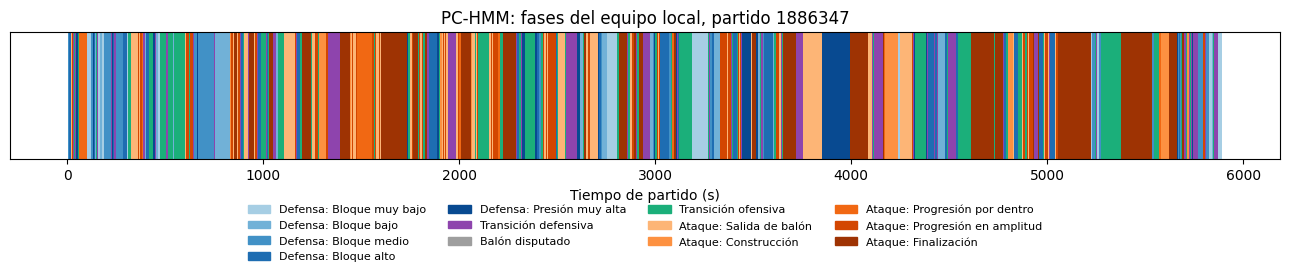

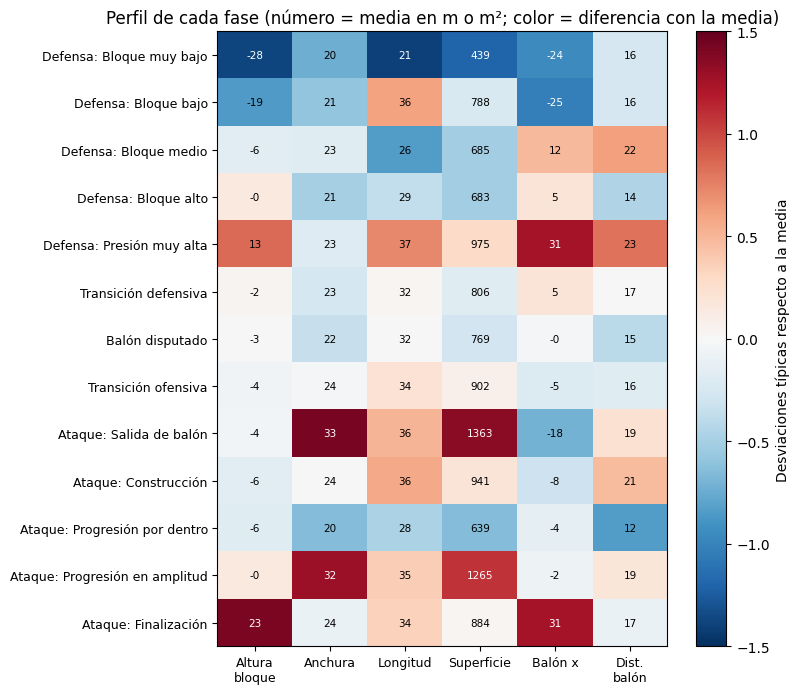

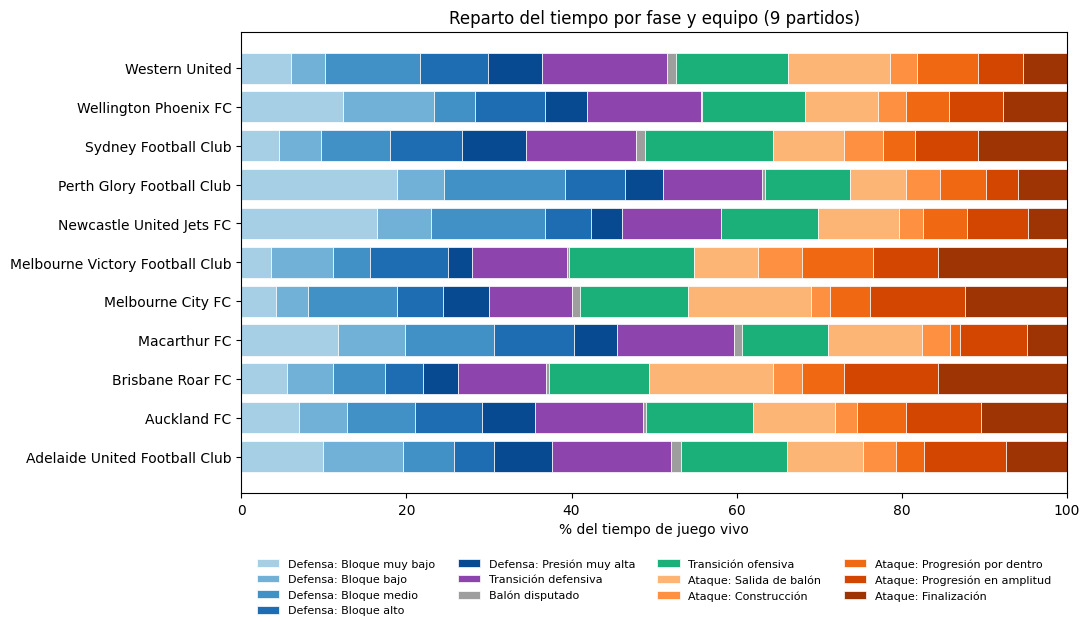

In [44]:
# ============================================================
# 5.7.6 Visualización del PC-HMM
# ============================================================
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def paleta_fases(orden):
    def_ = [f for f in orden if f.startswith('Defensa')]
    ata = [f for f in orden if f.startswith('Ataque')]
    azules = plt.cm.Blues(np.linspace(0.35, 0.9, len(def_)))
    naranjas = plt.cm.Oranges(np.linspace(0.35, 0.9, len(ata)))
    col = {f: azules[i] for i, f in enumerate(def_)}
    col.update({f: naranjas[i] for i, f in enumerate(ata)})
    col.update({'Transición defensiva': '#8e44ad', 'Transición ofensiva': '#1baf7a', 'Balón disputado': '#9e9e9e'})
    return col
COLORES_FASE = paleta_fases(ORDEN_FASES)

# (a) Línea temporal del partido de ejemplo
TEAM, MATCH_ID = 'home', 1886347
g = av[(av['match'] == MATCH_ID) & (av['team'] == TEAM)]
fig, ax = plt.subplots(figsize=(13, 3.2))
lab = g['fase_av'].to_numpy(); tt = g['frame'].to_numpy() / FPS_NATIVO
ini = np.r_[0, np.flatnonzero(lab[1:] != lab[:-1]) + 1]; fin = np.r_[ini[1:], len(lab)]
for a, b in zip(ini, fin):
    ax.axvspan(tt[a], tt[min(b, len(tt) - 1)], color=COLORES_FASE[lab[a]], lw=0)
ax.set_yticks([]); ax.set_xlabel('Tiempo de partido (s)')
ax.set_title(f'PC-HMM: fases del equipo local, partido {MATCH_ID}')
ax.legend(handles=[Patch(color=COLORES_FASE[f], label=f) for f in ORDEN_FASES],
          ncol=4, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.28), frameon=False)
plt.tight_layout(); plt.show()

# (b) Perfil normalizado de cada fase (z-score de las medias)
vars_perfil = ['centroide_x', 'anchura', 'longitud', 'superficie', 'balon_x', 'dist_balon']
m = av.groupby('fase_av')[vars_perfil].mean().loc[ORDEN_FASES]
z = (m - av[vars_perfil].mean()) / av[vars_perfil].std()
fig, ax = plt.subplots(figsize=(8, 0.45 * len(ORDEN_FASES) + 1.2))
im = ax.imshow(z.to_numpy(), cmap='RdBu_r', vmin=-1.5, vmax=1.5, aspect='auto')
ax.set_yticks(range(len(ORDEN_FASES))); ax.set_yticklabels(ORDEN_FASES, fontsize=9)
ax.set_xticks(range(len(vars_perfil)))
ax.set_xticklabels(['Altura\nbloque', 'Anchura', 'Longitud', 'Superficie', 'Balón x', 'Dist.\nbalón'], fontsize=9)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        ax.text(j, i, f'{m.iloc[i, j]:.0f}', ha='center', va='center', fontsize=7.5,
                color='white' if abs(z.iloc[i, j]) > 0.9 else 'black')
plt.colorbar(im, ax=ax, label='Desviaciones típicas respecto a la media')
ax.set_title('Perfil de cada fase (número = media en m o m²; color = diferencia con la media)')
plt.tight_layout(); plt.show()

# (c) Reparto del tiempo por fase para cada equipo (todos los partidos)
nombres_eq = {}
for mid, (ds_av, _) in datos_av.items():
    for eq in ds_av.metadata.teams:
        nombres_eq[eq.team_id] = eq.name
reparto = pd.crosstab(av['team_id'].map(nombres_eq), av['fase_av'], normalize='index')[ORDEN_FASES] * 100
fig, ax = plt.subplots(figsize=(11, 0.45 * len(reparto) + 1.5))
izq = np.zeros(len(reparto))
for f in ORDEN_FASES:
    ax.barh(reparto.index, reparto[f], left=izq, color=COLORES_FASE[f], label=f, edgecolor='white', linewidth=0.5)
    izq += reparto[f].to_numpy()
ax.set_xlabel('% del tiempo de juego vivo'); ax.set_xlim(0, 100)
ax.legend(ncol=4, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.12), frameon=False)
ax.set_title('Reparto del tiempo por fase y equipo (9 partidos)')
plt.tight_layout(); plt.show()

### 5.7.7 Comparación entre modelos

Para decidir qué modelo es mejor se comparan **cuatro versiones** sobre los mismos instantes (los frames comunes a 1 Hz y 2 Hz de los 18 equipos-partido):

| Modelo | Qué es |
|---|---|
| **A. Modelo base (TFM)** | K-means + HMM por partido y equipo, tal como está en las secciones 5.4-5.6 |
| **B. Modelo base corregido** | el mismo algoritmo (K-means para elegir k + HMM por partido y equipo), con las correcciones de escala temporal, orientación y anchura y con el mismo HMM pegajoso, pero sin posesión ni modelo compartido. Sirve para separar qué mejora se debe a corregir los datos y cuál al nuevo diseño |
| **C. PC-HMM (nuevo)** | el modelo de esta sección |
| Referencia: solo posesión | dos etiquetas (con balón / sin balón). Indica cuánto se consigue solo sabiendo quién tiene el balón |

Las métricas se eligen para medir cosas que un entrenador valora:

- **Acuerdo con SkillCorner (ARI y V-measure).** Cuánto se parecen las fases a las *Phases of Play* del proveedor, en la perspectiva de cada equipo. Ninguna de las dos es un ground truth perfecto, pero es la única referencia externa disponible.
- **Poder explicativo (η²).** Qué parte de la variación de la altura del bloque y de la posición del balón explican las fases (de 0 a 1). Si una fase dice "bloque alto", el bloque debería estar realmente alto.
- **Separación ataque/defensa.** Porcentaje de instantes en que la fase permite saber si el equipo tiene el balón.
- **Estabilidad temporal.** Duración media de las fases y número de cambios por minuto.
- **Generalización.** El PC-HMM se valida además por partidos: se entrena con 6 partidos y se evalúa en los 3 restantes, rotando tres veces. Un modelo que solo funciona con los datos con los que se entrenó no sirve para analizar al próximo rival.

El silhouette no se usa para comparar, porque cada modelo trabaja en un espacio de variables distinto y el PC-HMM no agrupa por distancias.

In [45]:
# ============================================================
# 5.7.7a Modelo B: base corregido (K-means + HMM por partido, datos corregidos)
# ============================================================
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

etiquetas_B = pd.Series(index=av.index, dtype=object)
for (mid, tm), g in av.groupby(['match', 'team'], sort=False):
    X = StandardScaler().fit_transform(g[VARS_NIVEL2])
    rng = np.random.RandomState(SEMILLA)
    muestra = rng.choice(len(X), size=min(4000, len(X)), replace=False)
    sil = {}
    for k in range(2, 9):
        km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X)
        sil[k] = silhouette_score(X[muestra], km.labels_[muestra])
    k = max(sil, key=sil.get)
    hmm = hmm_pegajoso(k, len(X)).fit(X)
    lab = hmm.predict(X)
    etiquetas_B.loc[g.index] = fusionar_cortos(lab, int(MIN_FASE_AV_S * HZ_AV))
av['fase_B'] = etiquetas_B.astype(str)
print('Modelo B: k elegido por silhouette en cada equipo-partido')
print(av.groupby(['match', 'team'])['fase_B'].nunique().value_counts().sort_index())

Modelo B: k elegido por silhouette en cada equipo-partido
fase_B
2     3
3    15
Name: count, dtype: int64


In [46]:
# ============================================================
# 5.7.7b Tabla común de evaluación (frames compartidos por todos los modelos)
# ============================================================
from sklearn.metrics import adjusted_rand_score, v_measure_score

filas = []
for team in ['home', 'away']:
    for mid, r in resultados[team].items():
        sub_A = r['sub'][['frame']].copy()
        sub_A['fase_A'] = r['labels_temporal']
        g = av[(av['match'] == mid) & (av['team'] == team)].merge(sub_A, on='frame', how='inner')
        fases_sc = cargar_fases_reales_skillcorner(mid)
        g['sc'] = construir_etiqueta_real(fases_sc, equipos_ids[mid][team], g['frame'].to_numpy())
        filas.append(g)
comun = pd.concat(filas, ignore_index=True)
comun = comun[comun['sc'].notna()].reset_index(drop=True)
comun['fase_A'] = comun['fase_A'].astype(str)
comun['solo_posesion'] = comun['posesion'].map({1: 'Con balón', 0: 'Sin balón'})
print('Instantes comunes evaluados:', len(comun), '| equipos-partido:', comun.groupby(['match', 'team']).ngroups)

Instantes comunes evaluados: 53292 | equipos-partido: 18


In [47]:
# ============================================================
# 5.7.7c Métricas por equipo-partido y generalización del PC-HMM
# ============================================================
def eta2(y, lab):
    """Proporción de la varianza de y explicada por las fases (correlation ratio)."""
    y = pd.Series(y).reset_index(drop=True); lab = pd.Series(lab).reset_index(drop=True)
    tot = ((y - y.mean()) ** 2).sum()
    intra = y.groupby(lab).transform(lambda v: v - v.mean()).pow(2).sum()
    return 1 - intra / tot if tot > 0 else np.nan

def pureza_posesion(lab, pos):
    tabla = pd.crosstab(pd.Series(lab).values, pd.Series(pos).values)
    return tabla.max(axis=1).sum() / tabla.to_numpy().sum()

def duracion_y_cambios(lab, segundos_por_frame):
    lab = np.asarray(lab)
    cambios = int((lab[1:] != lab[:-1]).sum())
    minutos = len(lab) * segundos_por_frame / 60
    return len(lab) * segundos_por_frame / (cambios + 1), cambios / minutos

MODELOS = {'A. Modelo base (TFM)': 'fase_A', 'B. Base corregido': 'fase_B',
           'C. PC-HMM (nuevo)': 'fase_av', 'Ref.: solo posesión': 'solo_posesion'}
res = []
for (mid, tm), g in comun.groupby(['match', 'team']):
    for nombre, col in MODELOS.items():
        dur, cpm = duracion_y_cambios(g[col], 1.0)   # frames comunes = 1 por segundo
        res.append({'modelo': nombre, 'match': mid, 'team': tm,
                    'n_fases': g[col].nunique(),
                    'ARI': adjusted_rand_score(g['sc'], g[col]),
                    'V-measure': v_measure_score(g['sc'], g[col]),
                    'eta2_altura': eta2(g['centroide_x'], g[col]),
                    'eta2_balon': eta2(g['balon_x'], g[col]),
                    'pureza_posesion': pureza_posesion(g[col], g['posesion']),
                    'dur_media_s': dur, 'cambios_min': cpm})
metricas = pd.DataFrame(res)

# Generalización del PC-HMM: 3 particiones por partido (entrena con 6, evalúa con 3).
# Se mantiene el número de sub-fases elegido con todos los datos.
K_ELEGIDO = {ctx: modelos_av[ctx][0].n_components for ctx in modelos_av}
bloques_cv = [MATCH_IDS[0::3], MATCH_IDS[1::3], MATCH_IDS[2::3]]
cv = []
for prueba in bloques_cv:
    entreno = av[~av['match'].isin(prueba)]
    mods, _ = entrenar_pc_hmm(entreno, k_fijo=K_ELEGIDO)
    test = av[av['match'].isin(prueba)]
    lab_test = aplicar_pc_hmm(test, mods)
    t2 = test.assign(fase_cv=lab_test)[['match', 'team', 'frame', 'fase_cv']]
    ev = comun.merge(t2, on=['match', 'team', 'frame'], how='inner')
    for (mid, tm), g in ev.groupby(['match', 'team']):
        cv.append({'match': mid, 'team': tm, 'ARI_cv': adjusted_rand_score(g['sc'], g['fase_cv']),
                   'V_cv': v_measure_score(g['sc'], g['fase_cv']),
                   'eta2_altura_cv': eta2(g['centroide_x'], g['fase_cv'])})
cv = pd.DataFrame(cv)
print('PC-HMM validado por partidos (media de 18 equipos-partido no vistos en el entrenamiento):')
print(cv[['ARI_cv', 'V_cv', 'eta2_altura_cv']].mean().round(3))

PC-HMM validado por partidos (media de 18 equipos-partido no vistos en el entrenamiento):
ARI_cv            0.163
V_cv              0.299
eta2_altura_cv    0.461
dtype: float64


### 5.7.8 Tabla comparativa final

La tabla resume las métricas anteriores (media de los 18 equipos-partido y, entre paréntesis, la desviación típica). La columna **Mejor** indica qué modelo gana en cada criterio, sin contar la referencia de solo posesión, que no es un modelo de fases sino un punto de comparación.

In [48]:
# ============================================================
# 5.7.8 Tabla comparativa final
# ============================================================
def fmt(serie, dec=3):
    return f'{serie.mean():.{dec}f} ({serie.std():.{dec}f})'.replace('.', ',')

CRITERIOS = [
    ('Nº de fases por equipo-partido', 'n_fases', 1, None),
    ('Acuerdo con SkillCorner: ARI', 'ARI', 3, 'max'),
    ('Acuerdo con SkillCorner: V-measure', 'V-measure', 3, 'max'),
    ('Poder explicativo: η² altura del bloque', 'eta2_altura', 3, 'max'),
    ('Poder explicativo: η² posición del balón', 'eta2_balon', 3, 'max'),
    ('Separación ataque/defensa (pureza de posesión)', 'pureza_posesion', 3, 'max'),
    ('Duración media de fase (s)', 'dur_media_s', 1, None),
    ('Cambios de fase por minuto', 'cambios_min', 2, None),
]
modelos_fase = [m for m in MODELOS if not m.startswith('Ref')]
tabla = {}
for texto, col, dec, sentido in CRITERIOS:
    fila = {m: fmt(metricas.loc[metricas['modelo'] == m, col], dec) for m in MODELOS}
    if sentido:
        medias = metricas[metricas['modelo'].isin(modelos_fase)].groupby('modelo')[col].mean()
        fila['Mejor'] = medias.idxmax()[:2].strip('. ')
    else:
        fila['Mejor'] = '(descriptivo)'
    tabla[texto] = fila
tabla['Fases con nombre futbolístico'] = {'A. Modelo base (TFM)': 'No (estado 0/1)', 'B. Base corregido': 'No',
                                        'C. PC-HMM (nuevo)': 'Sí', 'Ref.: solo posesión': 'Sí (2)', 'Mejor': 'C'}
tabla['Misma etiqueta en todos los partidos'] = {'A. Modelo base (TFM)': 'No', 'B. Base corregido': 'No',
                                               'C. PC-HMM (nuevo)': 'Sí', 'Ref.: solo posesión': 'Sí', 'Mejor': 'C'}
tabla['Validado en partidos no vistos (V-measure)'] = {'A. Modelo base (TFM)': 'No aplica', 'B. Base corregido': 'No aplica',
                                                     'C. PC-HMM (nuevo)': fmt(cv['V_cv']), 'Ref.: solo posesión': '-', 'Mejor': 'C'}
tabla_comparativa = pd.DataFrame(tabla).T
tabla_comparativa.to_csv('tabla_comparativa_modelos.csv')
tabla_comparativa

,A. Modelo base (TFM),B. Base corregido,C. PC-HMM (nuevo),Ref.: solo posesión,Mejor
Nº de fases por equipo-partido,"2,0 (0,0)","2,8 (0,4)","12,8 (0,4)","2,0 (0,0)",(descriptivo)
Acuerdo con SkillCorner: ARI,"0,087 (0,025)","0,167 (0,055)","0,178 (0,034)","0,129 (0,029)",C
Acuerdo con SkillCorner: V-measure,"0,140 (0,020)","0,234 (0,052)","0,302 (0,024)","0,177 (0,036)",C
Poder explicativo: η² altura del bloque,"0,286 (0,105)","0,353 (0,167)","0,445 (0,049)","0,044 (0,028)",C
Poder explicativo: η² posición del balón,"0,116 (0,096)","0,401 (0,196)","0,483 (0,023)","0,014 (0,019)",C
Separación ataque/defensa (pureza de posesión),"0,671 (0,064)","0,699 (0,055)","0,947 (0,006)","1,000 (0,000)",C
Duración media de fase (s),"119,8 (18,0)","18,8 (5,0)","8,6 (0,4)","13,0 (1,1)",(descriptivo)
Cambios de fase por minuto,"0,49 (0,08)","3,36 (0,72)","6,96 (0,30)","4,62 (0,40)",(descriptivo)
Fases con nombre futbolístico,No (estado 0/1),No,Sí,Sí (2),C
Misma etiqueta en todos los partidos,No,No,Sí,Sí,C


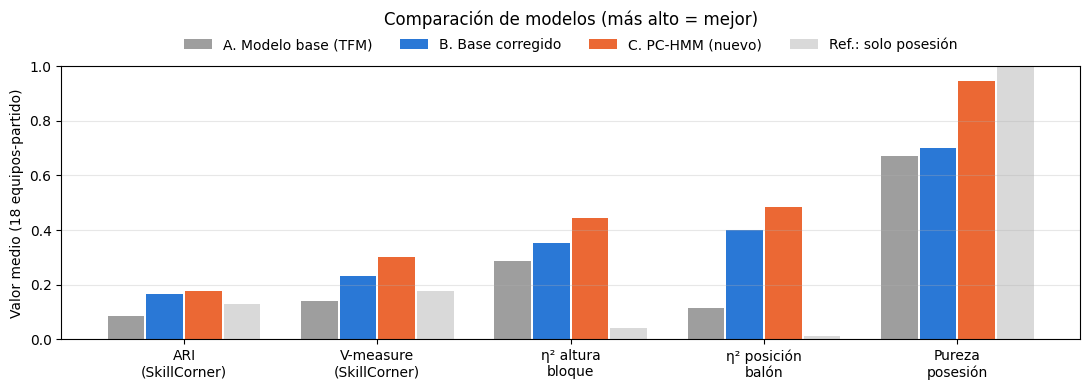

In [49]:
# ============================================================
# 5.7.8b Gráfico resumen de la comparación
# ============================================================
cols = ['ARI', 'V-measure', 'eta2_altura', 'eta2_balon', 'pureza_posesion']
etiquetas = ['ARI\n(SkillCorner)', 'V-measure\n(SkillCorner)', 'η² altura\nbloque', 'η² posición\nbalón', 'Pureza\nposesión']
medias = metricas.groupby('modelo')[cols].mean().loc[list(MODELOS)]
colores = ['#9e9e9e', '#2a78d6', '#eb6834', '#d9d9d9']
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(cols)); w = 0.2
for i, (m, c) in enumerate(zip(MODELOS, colores)):
    ax.bar(x + (i - 1.5) * w, medias.loc[m], w * 0.95, color=c, label=m)
ax.set_xticks(x); ax.set_xticklabels(etiquetas)
ax.set_ylabel('Valor medio (18 equipos-partido)'); ax.set_ylim(0, 1)
ax.grid(axis='y', alpha=0.3); ax.legend(ncol=4, frameon=False, loc='upper center', bbox_to_anchor=(0.5, 1.15))
ax.set_title('Comparación de modelos (más alto = mejor)', pad=30)
plt.tight_layout(); plt.show()

### 5.7.9 Conclusión: qué modelo es mejor

**El PC-HMM (modelo C) es el mejor en todos los criterios de la tabla.** Frente al modelo base del TFM (A):

- **Acuerdo con SkillCorner:** duplica el ARI (0,178 frente a 0,087) y el V-measure (0,302 frente a 0,140).
- **Poder explicativo:** las fases explican el 45 % de la variación de la altura del bloque (frente al 29 %) y el 48 % de la posición del balón (frente al 12 %). Cuando el modelo dice "bloque alto" o "finalización", el equipo y el balón están realmente ahí.
- **Separación de ataque y defensa:** acierta quién tiene el balón en el 95 % de los instantes, frente al 67 % del modelo base. El modelo base mezclaba ataque y defensa en sus dos estados.
- **Interpretabilidad:** pasa de dos estados sin nombre a 13 fases con nombre futbolístico (5 defensivas, 5 ofensivas, 2 transiciones y balón disputado), iguales en todos los partidos. Eso permite comparar equipos, como muestra el gráfico de reparto del tiempo.
- **Generalización:** entrenado con 6 partidos y evaluado en los 3 restantes mantiene el mismo rendimiento (V-measure 0,299 frente a 0,302), así que no está memorizando los partidos.

La comparación con el **modelo B** muestra de dónde sale la mejora. Solo con corregir los datos (escala temporal, orientación, anchura) y usar un HMM pegajoso, el algoritmo original ya mejora mucho (ARI 0,167, V-measure 0,234). Pero sigue sin separar ataque y defensa (70 %) y sus estados no tienen nombre ni son comparables entre partidos. Esas dos ventajas se deben al diseño del PC-HMM: la posesión como primer nivel y el modelo compartido.

La **referencia de solo posesión** confirma que el PC-HMM no se limita a copiar quién tiene el balón. Con solo esa información, el ARI es de 0,129 y las fases no explican nada de la altura del bloque (η² = 0,04). El PC-HMM añade la estructura espacial encima.

**Límites que conviene mencionar en la memoria:**

- Las fases del PC-HMM son más cortas (8,6 s de media, unos 7 cambios por minuto), porque el juego real cambia de contexto con frecuencia.
- El acuerdo con SkillCorner sigue siendo moderado en términos absolutos, porque ambas taxonomías no son equivalentes.
- La posesión procede del propio registro de SkillCorner, así que parte del acuerdo con sus fases se explica por compartir esa información. Por eso se incluye la referencia de solo posesión.
- Los umbrales del nivel 1 (5 s de transición, 3 s de balón disputado) son decisiones de diseño razonadas, no parámetros aprendidos.